# data understanding et data preparation

In [ ]:
!apt-get update > /dev/null 2>&1
!apt-get install -y p7zip-full p7zip-rar > /dev/null 2>&1
print("7zip installé ✅")

7zip installé ✅


In [ ]:
!pip install librosa soundfile pandas matplotlib seaborn

In [ ]:
# Cette commande essaie .7z puis .rar automatiquement, et force même si l'extension est .zip
!7z x "/content/TunSwitchTO.zip" -o/content/TunSwitchTO_extracted -y

print("\nDécompression FINIE ! 🎉")
!ls -la /content/TunSwitchTO_extracted


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/                   1 file, 92290570 bytes (89 MiB)

Extracting archive: /content/TunSwitchTO.zip
--
Path = /content/TunSwitchTO.zip
Type = zip
Physical Size = 92290570

  0%      5% 115 - TunSwitchTO/108_23_27_mqt.wav                                         11% 256 - TunSwitchTO/34_19_48_p0e.wav                                        17% 400 - TunSwitchTO/17_20_55_kk0.wav                                        24% 564 - TunSwitchTO/34_21_01_0s7.wav

In [ ]:
import os
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"

wav_files = [f for f in os.listdir(data_path) if f.endswith(".wav")]
print(f"Nombre de fichiers audio .wav : {len(wav_files)}")
print("Exemples :", wav_files[:10])


Nombre de fichiers audio .wav : 2240
Exemples : ['11_17_26_t5q.wav', '16_19_44_f0e.wav', '100_22_26_5xa.wav', '119_20_27_6fq.wav', '5_15_00_wzh.wav', '24_19_46_drd.wav', '32_23_51_t6y.wav', '55_19_34_86w.wav', '12_21_59_wr0.wav', '26_00_27_uil.wav']


exploring the csv

In [ ]:
import os

csv_files = [f for f in os.listdir(data_path) if f.endswith(".csv")]
print(f"Fichiers CSV trouvés : {csv_files}")


Fichiers CSV trouvés : ['train_normalized_clean.csv', 'test_normalized_clean.csv', 'dev.csv', 'train_normalized.csv', 'train_normalized_clean_v2.csv', 'train.csv', 'dev_normalized_clean_v2.csv', 'test_normalized_clean_v2.csv', 'dev_normalized_clean.csv', 'test.csv', 'test_normalized_with_ID.csv']


In [ ]:
import pandas as pd
import os

train_path = os.path.join(data_path, 'train.csv')
df_train = pd.read_csv(train_path)

# Aperçu général
print("Aperçu des premières lignes :")
print(df_train.head())

print("\nInformations sur les colonnes :")
print(df_train.info())

# Voir les colonnes disponibles
print("\nColonnes disponibles :", df_train.columns)


Aperçu des premières lignes :
                  ID                            wav  \
0   11_15:19_g6j.wav   audio_files/11_15:19_g6j.wav   
1   80_15:03_vsh.wav   audio_files/80_15:03_vsh.wav   
2  136_01:37_y9b.wav  audio_files/136_01:37_y9b.wav   
3   21_00:23_ss0.wav   audio_files/21_00:23_ss0.wav   
4   43_21:04_cxx.wav   audio_files/43_21:04_cxx.wav   

                                                 wrd  duration  
0  اسمي يمينة واخترت هذه الصورة لاني جزائرية و اق...      8.58  
1  وضحونا أمورنا على الاقل لجيل كامل قادم للتعليق...      8.64  
2                   فماشي حوانيت شاملة قريبة مه هوني      4.26  
3                 فما بارشا عباد في الرحلات السياحية      2.52  
4        شركة الطيران باش تدفعلي شراء حوايجي الشخصية      3.66  

Informations sur les colonnes :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2128 entries, 0 to 2127
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        2128 non-null   o

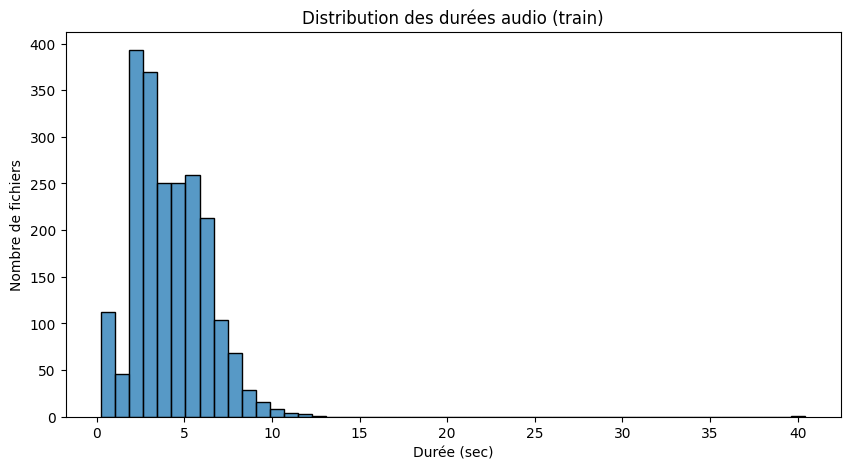

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.histplot(df_train['duration'], bins=50)
plt.xlabel("Durée (sec)")
plt.ylabel("Nombre de fichiers")
plt.title("Distribution des durées audio (train)")
plt.show()


count    2128.000000
mean        8.309680
std         4.407697
min         1.000000
25%         4.000000
50%         7.500000
75%        12.000000
max        23.000000
Name: transcription_length, dtype: float64


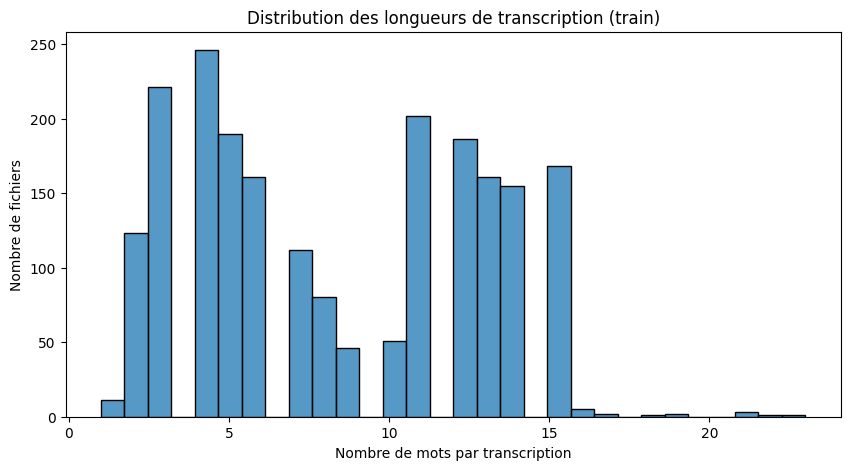

In [ ]:
df_train['transcription_length'] = df_train['wrd'].apply(lambda x: len(str(x).split()))

print(df_train['transcription_length'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df_train['transcription_length'], bins=30)
plt.xlabel("Nombre de mots par transcription")
plt.ylabel("Nombre de fichiers")
plt.title("Distribution des longueurs de transcription (train)")
plt.show()


In [ ]:
# Vérifier les fichiers audio en utilisant la colonne 'wav' du CSV
missing_files = []
for f in df_train['wav']:
    full_path = os.path.join(data_path, f)  # data_path = /content/TunSwitchTO_extracted/TunSwitchTO
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants : {len(missing_files)}")

if len(missing_files) > 0:
    print("Exemples de fichiers manquants :", missing_files[:10])
else:
    print("Tous les fichiers audio du train.csv existent ✅")


Nombre de fichiers manquants : 2128
Exemples de fichiers manquants : ['audio_files/11_15:19_g6j.wav', 'audio_files/80_15:03_vsh.wav', 'audio_files/136_01:37_y9b.wav', 'audio_files/21_00:23_ss0.wav', 'audio_files/43_21:04_cxx.wav', 'audio_files/59_22:16_s3i.wav', 'audio_files/61_09:16_mvg.wav', 'audio_files/3_08:53_zn0.wav', 'audio_files/8_10:37_2d2.wav', 'audio_files/115_00:21_tbz.wav']


In [ ]:
import pandas as pd
import os

# Chemin vers le dossier extrait
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"

# Liste des CSV
csv_files = ['train.csv', 'dev.csv', 'test.csv']

for csv_file in csv_files:
    csv_path = os.path.join(data_path, csv_file)
    df = pd.read_csv(csv_path)

    # Vérifier chaque fichier audio selon la colonne 'wav'
    missing_files = []
    for f in df['wav']:
        full_path = os.path.join(data_path, f)
        if not os.path.isfile(full_path):
            missing_files.append(f)

    print(f"\n--- {csv_file} ---")
    print(f"Nombre total de fichiers listés : {len(df)}")
    print(f"Nombre de fichiers manquants : {len(missing_files)}")
    if len(missing_files) > 0:
        print("Exemples de fichiers manquants :", missing_files[:10])
    else:
        print("Tous les fichiers audio existent ✅")



--- train.csv ---
Nombre total de fichiers listés : 2128
Nombre de fichiers manquants : 2128
Exemples de fichiers manquants : ['audio_files/11_15:19_g6j.wav', 'audio_files/80_15:03_vsh.wav', 'audio_files/136_01:37_y9b.wav', 'audio_files/21_00:23_ss0.wav', 'audio_files/43_21:04_cxx.wav', 'audio_files/59_22:16_s3i.wav', 'audio_files/61_09:16_mvg.wav', 'audio_files/3_08:53_zn0.wav', 'audio_files/8_10:37_2d2.wav', 'audio_files/115_00:21_tbz.wav']

--- dev.csv ---
Nombre total de fichiers listés : 67
Nombre de fichiers manquants : 67
Exemples de fichiers manquants : ['audio_files/20_22:00_mjr.wav', 'audio_files/62_02:19_quc.wav', 'audio_files/78_22:23_82f.wav', 'audio_files/31_21:52_s6d.wav', 'audio_files/123_15:09_go2.wav', 'audio_files/3_12:47_l7u.wav', 'audio_files/43_13:00_ymu.wav', 'audio_files/61_14:26_nq3.wav', 'audio_files/14_13:55_1r1.wav', 'audio_files/94_22:46_vrc.wav']

--- test.csv ---
Nombre total de fichiers listés : 344
Nombre de fichiers manquants : 344
Exemples de fichier

In [ ]:
import os
import pandas as pd

# Chemin vers le dossier contenant tous les fichiers
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
train_csv_path = os.path.join(data_path, "train.csv")

# Charger le CSV
df_train = pd.read_csv(train_csv_path)

# Normaliser la colonne 'ID' : remplacer ':' par '_' et ajouter l'extension .wav si nécessaire
df_train['ID_normalized'] = df_train['ID'].str.replace(':', '_')
df_train['ID_normalized'] = df_train['ID_normalized'].apply(lambda x: x if x.endswith('.wav') else x + '.wav')

# Normaliser la colonne 'wav' : remplacer ':' par '_' et supprimer 'audio_files/' si présent
df_train['wav_normalized'] = df_train['wav'].str.replace(':', '_').str.replace('audio_files/', '')

# Vérifier l'existence des fichiers
missing_files = []
for f in df_train['wav_normalized']:
    full_path = os.path.join(data_path, f)  # chemin complet
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants : {len(missing_files)}")
if missing_files:
    print("Exemples de fichiers manquants :", missing_files[:10])
else:
    print("Tous les fichiers audio existent ✅")

# Enregistrer le CSV avec la colonne 'ID_normalized'
output_csv_path = os.path.join(data_path, "train_normalized.csv")
df_train.to_csv(output_csv_path, index=False)
print(f"\nCSV avec colonne 'ID_normalized' enregistré ici : {output_csv_path}")


Nombre de fichiers manquants : 0
Tous les fichiers audio existent ✅

CSV avec colonne 'ID_normalized' enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/train_normalized.csv


In [ ]:
import os
import pandas as pd

data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
csv_splits = ['dev.csv', 'test.csv']

for csv_file in csv_splits:
    csv_path = os.path.join(data_path, csv_file)
    df = pd.read_csv(csv_path)

    # Normaliser la colonne 'wav' : remplacer ':' par '_' et supprimer 'audio_files/' si présent
    df['wav_normalized'] = df['wav'].str.replace(':', '_').str.replace('audio_files/', '')

    # Vérifier l'existence des fichiers
    missing_files = []
    for f in df['wav_normalized']:
        full_path = os.path.join(data_path, f)
        if not os.path.isfile(full_path):
            missing_files.append(f)

    print(f"\n--- {csv_file} ---")
    print(f"Nombre total de fichiers listés : {len(df)}")
    print(f"Nombre de fichiers manquants : {len(missing_files)}")
    if len(missing_files) > 0:
        print("Exemples de fichiers manquants :", missing_files[:10])
    else:
        print("Tous les fichiers audio existent ✅")



--- dev.csv ---
Nombre total de fichiers listés : 67
Nombre de fichiers manquants : 0
Tous les fichiers audio existent ✅

--- test.csv ---
Nombre total de fichiers listés : 344
Nombre de fichiers manquants : 344
Exemples de fichiers manquants : ['/gpfsscratch/rech/nou/uzn19yk/annotation_tool/33_09_06_eod.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/32_02_10_vwg.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/5_12_48_m3n.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/36_19_26_893.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/14_18_51_0vp.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/30_20_59_oiq.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/13_18_51_d2p.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/3_17_20_glk.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/54_22_06_l6y.wav', '/gpfsscratch/rech/nou/uzn19yk/annotation_tool/21_13_50_p43.wav']


In [ ]:
import os
os.path.getsize("/content/test_wavs.zip")  # doit correspondre à la taille attendue


284095903

In [ ]:
# Décompression avec 7zip
!7z x "/content/test_wavs.zip" -o/content/test_wavs_extracted -y


print("\nDécompression FINIE ! 🎉")

# Lister le contenu du dossier extrait
!ls -la /content/test_wavs_extracted



7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/                   1 file, 284095903 bytes (271 MiB)

Extracting archive: /content/test_wavs.zip
--
Path = /content/test_wavs.zip
Type = zip
Physical Size = 284095903

  0%      3% 32 - test_wavs/97_375.wav                                6% 58 - test_wavs/71_19_24_4dr.wav                                     10% 81 - test_wavs/28_111_3.wav                                 12% 93 - test_wavs/17_21_39_4gu.wav                                    

In [ ]:
import pandas as pd
import os

data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
test_csv_path = os.path.join(data_path, "test.csv")
test_wavs_path = "/content/test_wavs_extracted/test_wavs"

df_test = pd.read_csv(test_csv_path)

# Normaliser : remplacer ':' par '_' et ajouter .wav seulement si nécessaire
df_test['ID_normalized'] = df_test['ID'].str.replace(':', '_')
df_test['ID_normalized'] = df_test['ID_normalized'].apply(lambda x: x if x.endswith('.wav') else x + '.wav')

# Vérifier l'existence dans test_wavs
missing_files = []
for f in df_test['ID_normalized']:
    full_path = os.path.join(test_wavs_path, f)
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants après correction : {len(missing_files)}")
if missing_files:
    print("Exemples :", missing_files[:10])
else:
    print("Tous les fichiers test.csv existent dans test_wavs ✅")


Nombre de fichiers manquants après correction : 0
Tous les fichiers test.csv existent dans test_wavs ✅


In [ ]:
import pandas as pd
import os

# Chemin vers le CSV normalisé
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
train_norm_csv_path = os.path.join(data_path, "train_normalized.csv")

# Charger le CSV normalisé
df_train_norm = pd.read_csv(train_norm_csv_path)

# Aperçu des premières lignes
print("=== Aperçu des premières lignes ===")
display(df_train_norm.head(10))

# Informations générales sur le CSV
print("\n=== Informations sur les colonnes et types de données ===")
print(df_train_norm.info())

# Statistiques descriptives pour les colonnes numériques
print("\n=== Statistiques descriptives ===")
print(df_train_norm.describe())

# Colonnes disponibles
print("\n=== Colonnes disponibles ===")
print(df_train_norm.columns.tolist())


=== Aperçu des premières lignes ===


,ID,wav,wrd,duration,ID_normalized,wav_normalized
0,11_15:19_g6j.wav,audio_files/11_15:19_g6j.wav,اسمي يمينة واخترت هذه الصورة لاني جزائرية و اق...,8.58,11_15_19_g6j.wav,11_15_19_g6j.wav
1,80_15:03_vsh.wav,audio_files/80_15:03_vsh.wav,وضحونا أمورنا على الاقل لجيل كامل قادم للتعليق...,8.64,80_15_03_vsh.wav,80_15_03_vsh.wav
2,136_01:37_y9b.wav,audio_files/136_01:37_y9b.wav,فماشي حوانيت شاملة قريبة مه هوني,4.26,136_01_37_y9b.wav,136_01_37_y9b.wav
3,21_00:23_ss0.wav,audio_files/21_00:23_ss0.wav,فما بارشا عباد في الرحلات السياحية,2.52,21_00_23_ss0.wav,21_00_23_ss0.wav
4,43_21:04_cxx.wav,audio_files/43_21:04_cxx.wav,شركة الطيران باش تدفعلي شراء حوايجي الشخصية,3.66,43_21_04_cxx.wav,43_21_04_cxx.wav
5,59_22:16_s3i.wav,audio_files/59_22:16_s3i.wav,قتلك هيا كول لا يبرد سخون خير يولي كاوتشو نزيد...,5.40,59_22_16_s3i.wav,59_22_16_s3i.wav
6,61_09:16_mvg.wav,audio_files/61_09:16_mvg.wav,وقت اراحا راحا حد ما يوقفني ما يقلقني ما يفيقن...,7.20,61_09_16_mvg.wav,61_09_16_mvg.wav
7,3_08:53_zn0.wav,audio_files/3_08:53_zn0.wav,أهو بارد شوية تنجم تسخنه,3.78,3_08_53_zn0.wav,3_08_53_zn0.wav
8,8_10:37_2d2.wav,audio_files/8_10:37_2d2.wav,دقيقات اخرين يعيشك,1.62,8_10_37_2d2.wav,8_10_37_2d2.wav
9,115_00:21_tbz.wav,audio_files/115_00:21_tbz.wav,الكلام حاجة والواقع حاجة اخرى انا متاكد انو شط...,4.74,115_00_21_tbz.wav,115_00_21_tbz.wav



=== Informations sur les colonnes et types de données ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2128 entries, 0 to 2127
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              2128 non-null   object 
 1   wav             2128 non-null   object 
 2   wrd             2128 non-null   object 
 3   duration        2128 non-null   float64
 4   ID_normalized   2128 non-null   object 
 5   wav_normalized  2128 non-null   object 
dtypes: float64(1), object(5)
memory usage: 99.9+ KB
None

=== Statistiques descriptives ===
          duration
count  2128.000000
mean      4.215115
std       2.128777
min       0.240000
25%       2.640000
50%       3.840000
75%       5.580000
max      40.440000

=== Colonnes disponibles ===
['ID', 'wav', 'wrd', 'duration', 'ID_normalized', 'wav_normalized']


In [ ]:
import pandas as pd
import os

# Chemin vers le CSV normalisé
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
train_norm_csv_path = os.path.join(data_path, "train_normalized.csv")

# Charger le CSV
df_train_norm = pd.read_csv(train_norm_csv_path)

# Supprimer les colonnes 'ID' et 'wav'
df_train_norm = df_train_norm.drop(columns=['ID', 'wav'])

# Enregistrer le CSV modifié
output_csv_path = os.path.join(data_path, "train_normalized_clean.csv")
df_train_norm.to_csv(output_csv_path, index=False)

print(f"CSV modifié enregistré ici : {output_csv_path}")


CSV modifié enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/train_normalized_clean.csv


In [ ]:
import pandas as pd
import os

# Chemin vers le CSV nettoyé
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
train_clean_csv_path = os.path.join(data_path, "train_normalized_clean.csv")

# Charger le CSV
df_train_clean = pd.read_csv(train_clean_csv_path)

# 1️⃣ Explorer les premières lignes
print("=== Aperçu des premières lignes ===")
display(df_train_clean.head(10))

# 2️⃣ Informations sur le DataFrame
print("\n=== Informations sur les colonnes et types de données ===")
print(df_train_clean.info())

# 3️⃣ Statistiques descriptives pour les colonnes numériques
print("\n=== Statistiques descriptives ===")
print(df_train_clean.describe())

# 4️⃣ Colonnes disponibles
print("\n=== Colonnes disponibles ===")
print(df_train_clean.columns.tolist())

# 5️⃣ Vérifier que tous les ID_normalized correspondent à un fichier audio existant
missing_files = []
for f in df_train_clean['ID_normalized']:
    full_path = os.path.join(data_path, f)
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"\nNombre de fichiers manquants : {len(missing_files)}")
if missing_files:
    print("Exemples de fichiers manquants :", missing_files[:10])
else:
    print("Tous les fichiers ID_normalized correspondent à un fichier audio ✅")


=== Aperçu des premières lignes ===


,wrd,duration,ID_normalized,wav_normalized
0,اسمي يمينة واخترت هذه الصورة لاني جزائرية و اق...,8.58,11_15_19_g6j.wav,11_15_19_g6j.wav
1,وضحونا أمورنا على الاقل لجيل كامل قادم للتعليق...,8.64,80_15_03_vsh.wav,80_15_03_vsh.wav
2,فماشي حوانيت شاملة قريبة مه هوني,4.26,136_01_37_y9b.wav,136_01_37_y9b.wav
3,فما بارشا عباد في الرحلات السياحية,2.52,21_00_23_ss0.wav,21_00_23_ss0.wav
4,شركة الطيران باش تدفعلي شراء حوايجي الشخصية,3.66,43_21_04_cxx.wav,43_21_04_cxx.wav
5,قتلك هيا كول لا يبرد سخون خير يولي كاوتشو نزيد...,5.40,59_22_16_s3i.wav,59_22_16_s3i.wav
6,وقت اراحا راحا حد ما يوقفني ما يقلقني ما يفيقن...,7.20,61_09_16_mvg.wav,61_09_16_mvg.wav
7,أهو بارد شوية تنجم تسخنه,3.78,3_08_53_zn0.wav,3_08_53_zn0.wav
8,دقيقات اخرين يعيشك,1.62,8_10_37_2d2.wav,8_10_37_2d2.wav
9,الكلام حاجة والواقع حاجة اخرى انا متاكد انو شط...,4.74,115_00_21_tbz.wav,115_00_21_tbz.wav



=== Informations sur les colonnes et types de données ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2128 entries, 0 to 2127
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   wrd             2128 non-null   object 
 1   duration        2128 non-null   float64
 2   ID_normalized   2128 non-null   object 
 3   wav_normalized  2128 non-null   object 
dtypes: float64(1), object(3)
memory usage: 66.6+ KB
None

=== Statistiques descriptives ===
          duration
count  2128.000000
mean      4.215115
std       2.128777
min       0.240000
25%       2.640000
50%       3.840000
75%       5.580000
max      40.440000

=== Colonnes disponibles ===
['wrd', 'duration', 'ID_normalized', 'wav_normalized']

Nombre de fichiers manquants : 0
Tous les fichiers ID_normalized correspondent à un fichier audio ✅


In [ ]:
# Vérifier si toutes les valeurs sont identiques
all_equal = (df_train_clean['ID_normalized'] == df_train_clean['wav_normalized']).all()
print(f"Toutes les lignes ont ID_normalized == wav_normalized ? {all_equal}")

# Si c'est vrai, on peut supprimer 'ID_normalized'
if all_equal:
    df_train_clean = df_train_clean.drop(columns=['ID_normalized'])
    # Réenregistrer le CSV
    output_csv_path = os.path.join(data_path, "train_normalized_clean_v2.csv")
    df_train_clean.to_csv(output_csv_path, index=False)
    print(f"\nColonne 'ID_normalized' supprimée, CSV enregistré ici : {output_csv_path}")
else:
    print("Certaines lignes ont des valeurs différentes, on garde les deux colonnes.")


Toutes les lignes ont ID_normalized == wav_normalized ? True

Colonne 'ID_normalized' supprimée, CSV enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/train_normalized_clean_v2.csv


In [ ]:
import pandas as pd
import os

# Chemin vers le CSV final
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
train_final_csv = os.path.join(data_path, "train_normalized_clean_v2.csv")

# Charger le CSV
df_train_final = pd.read_csv(train_final_csv)

# Aperçu des premières lignes
print("=== Aperçu des premières lignes ===")
display(df_train_final.head(10))

# Informations sur les colonnes et types
print("\n=== Informations sur les colonnes et types de données ===")
print(df_train_final.info())

# Statistiques descriptives pour les colonnes numériques
print("\n=== Statistiques descriptives ===")
print(df_train_final.describe())

# Colonnes disponibles
print("\n=== Colonnes disponibles ===")
print(df_train_final.columns.tolist())


=== Aperçu des premières lignes ===


,wrd,duration,wav_normalized
0,اسمي يمينة واخترت هذه الصورة لاني جزائرية و اق...,8.58,11_15_19_g6j.wav
1,وضحونا أمورنا على الاقل لجيل كامل قادم للتعليق...,8.64,80_15_03_vsh.wav
2,فماشي حوانيت شاملة قريبة مه هوني,4.26,136_01_37_y9b.wav
3,فما بارشا عباد في الرحلات السياحية,2.52,21_00_23_ss0.wav
4,شركة الطيران باش تدفعلي شراء حوايجي الشخصية,3.66,43_21_04_cxx.wav
5,قتلك هيا كول لا يبرد سخون خير يولي كاوتشو نزيد...,5.40,59_22_16_s3i.wav
6,وقت اراحا راحا حد ما يوقفني ما يقلقني ما يفيقن...,7.20,61_09_16_mvg.wav
7,أهو بارد شوية تنجم تسخنه,3.78,3_08_53_zn0.wav
8,دقيقات اخرين يعيشك,1.62,8_10_37_2d2.wav
9,الكلام حاجة والواقع حاجة اخرى انا متاكد انو شط...,4.74,115_00_21_tbz.wav



=== Informations sur les colonnes et types de données ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2128 entries, 0 to 2127
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   wrd             2128 non-null   object 
 1   duration        2128 non-null   float64
 2   wav_normalized  2128 non-null   object 
dtypes: float64(1), object(2)
memory usage: 50.0+ KB
None

=== Statistiques descriptives ===
          duration
count  2128.000000
mean      4.215115
std       2.128777
min       0.240000
25%       2.640000
50%       3.840000
75%       5.580000
max      40.440000

=== Colonnes disponibles ===
['wrd', 'duration', 'wav_normalized']


dev cleaning

In [ ]:
import os
import pandas as pd

# Chemin vers le dossier contenant tous les fichiers
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
dev_csv_path = os.path.join(data_path, "dev.csv")

# Charger le CSV
df_dev = pd.read_csv(dev_csv_path)

# Normaliser la colonne 'wav' (remplacer ':' par '_') et supprimer 'audio_files/' si présent
df_dev['wav_normalized'] = df_dev['wav'].str.replace(':', '_').str.replace('audio_files/', '')

# Vérifier l'existence des fichiers
missing_files = []
for f in df_dev['wav_normalized']:
    full_path = os.path.join(data_path, f)  # chemin complet
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants : {len(missing_files)}")
if missing_files:
    print("Exemples de fichiers manquants :", missing_files[:10])
else:
    print("Tous les fichiers audio existent ✅")

# Ajouter une colonne 'ID_normalized' pour correspondre au train.csv
df_dev['ID_normalized'] = df_dev['wav_normalized']

# Explorer le DataFrame
print("\n=== Aperçu des premières lignes ===")
display(df_dev.head(10))

print("\n=== Statistiques descriptives ===")
print(df_dev.describe())

# Supprimer les colonnes originales 'ID' et 'wav' pour ne garder que la version normalisée
df_dev_clean = df_dev.drop(columns=['ID', 'wav'])

# Enregistrer le CSV nettoyé
dev_clean_csv_path = os.path.join(data_path, "dev_normalized_clean.csv")
df_dev_clean.to_csv(dev_clean_csv_path, index=False)
print(f"\nCSV dev nettoyé enregistré ici : {dev_clean_csv_path}")


Nombre de fichiers manquants : 0
Tous les fichiers audio existent ✅

=== Aperçu des premières lignes ===


,ID,wav,wrd,duration,wav_normalized,ID_normalized
0,20_22:00_mjr.wav,audio_files/20_22:00_mjr.wav,يظهرلي اللي الدينا ولات تمشي بالمقلوب مادام كل...,5.70,20_22_00_mjr.wav,20_22_00_mjr.wav
1,62_02:19_quc.wav,audio_files/62_02:19_quc.wav,ميدة و جراية في دار مماتي ما كان حد يعاملني با...,4.62,62_02_19_quc.wav,62_02_19_quc.wav
2,78_22:23_82f.wav,audio_files/78_22:23_82f.wav,كان تجيني وقتلي نبدى بين يدين قيصر خاطر اقصى م...,5.46,78_22_23_82f.wav,78_22_23_82f.wav
3,31_21:52_s6d.wav,audio_files/31_21:52_s6d.wav,البنات على خاطر برشة أسباب التصوحيب مضيعة للوق...,6.84,31_21_52_s6d.wav,31_21_52_s6d.wav
4,123_15:09_go2.wav,audio_files/123_15:09_go2.wav,زهر الرعد زدم طوفان شعل بركان المحرم تذاق القل...,10.26,123_15_09_go2.wav,123_15_09_go2.wav
5,3_12:47_l7u.wav,audio_files/3_12:47_l7u.wav,صلحه او بدله يعيشك,2.94,3_12_47_l7u.wav,3_12_47_l7u.wav
6,43_13:00_ymu.wav,audio_files/43_13:00_ymu.wav,عندي تسكرة لسان فرانسيسكو,2.52,43_13_00_ymu.wav,43_13_00_ymu.wav
7,61_14:26_nq3.wav,audio_files/61_14:26_nq3.wav,ملح يعيشك,2.28,61_14_26_nq3.wav,61_14_26_nq3.wav
8,14_13:55_1r1.wav,audio_files/14_13:55_1r1.wav,فما زيارة للبلاد,2.82,14_13_55_1r1.wav,14_13_55_1r1.wav
9,94_22:46_vrc.wav,audio_files/94_22:46_vrc.wav,النوع هذا موجود في الثمنية و عشرين واحد و ثلاث...,6.42,94_22_46_vrc.wav,94_22_46_vrc.wav



=== Statistiques descriptives ===
        duration
count  67.000000
mean    3.961853
std     1.935878
min     0.981375
25%     2.670000
50%     3.240000
75%     5.220000
max    10.260000

CSV dev nettoyé enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/dev_normalized_clean.csv


In [ ]:
import pandas as pd
import os

data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
dev_clean_csv_path = os.path.join(data_path, "dev_normalized_clean.csv")

# Charger le CSV
df_dev = pd.read_csv(dev_clean_csv_path)

# Vérifier si ID_normalized et wav_normalized ont la même valeur pour toutes les lignes
all_equal = (df_dev['ID_normalized'] == df_dev['wav_normalized']).all()
print(f"Toutes les lignes ont ID_normalized == wav_normalized ? {all_equal}")

# Supprimer ID_normalized si tout est égal
if all_equal:
    df_dev = df_dev.drop(columns=['ID_normalized'])

# Enregistrer le CSV final
final_dev_csv_path = os.path.join(data_path, "dev_normalized_clean_v2.csv")
df_dev.to_csv(final_dev_csv_path, index=False)
print(f"CSV dev final enregistré ici : {final_dev_csv_path}")


Toutes les lignes ont ID_normalized == wav_normalized ? True
CSV dev final enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/dev_normalized_clean_v2.csv


In [ ]:
import pandas as pd
import os

data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
final_dev_csv_path = os.path.join(data_path, "dev_normalized_clean_v2.csv")

# Charger le CSV
df_dev = pd.read_csv(final_dev_csv_path)

# Aperçu des premières lignes
print("=== Aperçu des premières lignes ===")
print(df_dev.head(10))

# Informations sur les colonnes et types de données
print("\n=== Informations sur les colonnes et types de données ===")
print(df_dev.info())

# Statistiques descriptives pour 'duration'
print("\n=== Statistiques descriptives ===")
print(df_dev['duration'].describe())

# Colonnes disponibles
print("\n=== Colonnes disponibles ===")
print(df_dev.columns.tolist())


=== Aperçu des premières lignes ===
                                                 wrd  duration  \
0  يظهرلي اللي الدينا ولات تمشي بالمقلوب مادام كل...      5.70   
1  ميدة و جراية في دار مماتي ما كان حد يعاملني با...      4.62   
2  كان تجيني وقتلي نبدى بين يدين قيصر خاطر اقصى م...      5.46   
3  البنات على خاطر برشة أسباب التصوحيب مضيعة للوق...      6.84   
4  زهر الرعد زدم طوفان شعل بركان المحرم تذاق القل...     10.26   
5                                 صلحه او بدله يعيشك      2.94   
6                          عندي تسكرة لسان فرانسيسكو      2.52   
7                                          ملح يعيشك      2.28   
8                                   فما زيارة للبلاد      2.82   
9  النوع هذا موجود في الثمنية و عشرين واحد و ثلاث...      6.42   

      wav_normalized  
0   20_22_00_mjr.wav  
1   62_02_19_quc.wav  
2   78_22_23_82f.wav  
3   31_21_52_s6d.wav  
4  123_15_09_go2.wav  
5    3_12_47_l7u.wav  
6   43_13_00_ymu.wav  
7   61_14_26_nq3.wav  
8   14_13_55_1r1.wav  
9   94_

test dataset cleaning

In [ ]:
import os
import pandas as pd

# Chemins
test_csv_path = "/content/TunSwitchTO_extracted/TunSwitchTO/test.csv"
test_wavs_path = "/content/test_wavs_extracted/test_wavs"
output_csv_path = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean.csv"

# Charger le CSV
df_test = pd.read_csv(test_csv_path)

# Normaliser la colonne 'ID' ou 'wav' : remplacer ':' par '_'
# Ajouter l'extension .wav si nécessaire
df_test['ID_normalized'] = df_test['ID'].str.replace(':', '_')
df_test['ID_normalized'] = df_test['ID_normalized'].apply(lambda x: x if x.endswith('.wav') else x + '.wav')

# Vérifier que tous les fichiers existent dans le dossier test_wavs
missing_files = []
for f in df_test['ID_normalized']:
    full_path = os.path.join(test_wavs_path, f)
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants : {len(missing_files)}")
if missing_files:
    print("Exemples :", missing_files[:10])
else:
    print("Tous les fichiers audio test.csv existent dans test_wavs ✅")

# Ajouter une colonne wav_normalized identique à ID_normalized
df_test['wav_normalized'] = df_test['ID_normalized']

# Vérifier si toutes les lignes ont la même valeur pour ID_normalized et wav_normalized
if (df_test['ID_normalized'] == df_test['wav_normalized']).all():
    df_test = df_test.drop(columns=['ID_normalized', 'wav'])  # supprimer ID et wav originaux
else:
    print("Attention : ID_normalized et wav_normalized diffèrent pour certaines lignes")

# Enregistrer le CSV nettoyé
df_test.to_csv(output_csv_path, index=False)
print(f"CSV test nettoyé enregistré ici : {output_csv_path}")

# Aperçu du fichier
print("\n=== Aperçu des premières lignes ===")
display(df_test.head())


Nombre de fichiers manquants : 0
Tous les fichiers audio test.csv existent dans test_wavs ✅
CSV test nettoyé enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean.csv

=== Aperçu des premières lignes ===


,Unnamed: 0,ID,wrd,duration,wav_normalized
0,974,33_09:06_eod.wav,بدلي بلاستي من فضلك,2.76,33_09_06_eod.wav
1,111,32_02:10_vwg.wav,ولا هم عندهم حساباتهم طفيهم معادش تتفرج عليهم ...,5.82,32_02_10_vwg.wav
2,1061,5_12:48_m3n.wav,رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثي...,8.64,5_12_48_m3n.wav
3,251,36_19:26_893.wav,ثمة شق كبير يدعم الحكومة و يدعو إلى الهدوء اذا...,4.98,36_19_26_893.wav
4,2074,14_18:51_0vp.wav,نحب نبعث هاذا للغسالة وقتاش يحضر,3.30,14_18_51_0vp.wav


In [ ]:
import os
import pandas as pd

# Chemins
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
test_csv_path = os.path.join(data_path, "test.csv")
test_wavs_path = "/content/test_wavs_extracted/test_wavs"
output_csv_path = os.path.join(data_path, "test_normalized_with_ID.csv")

# Charger le CSV
df_test = pd.read_csv(test_csv_path)

# Supprimer la colonne Unnamed: 0 si elle existe
if 'Unnamed: 0' in df_test.columns:
    df_test = df_test.drop(columns=['Unnamed: 0'])

# Normaliser la colonne ID : remplacer ':' par '_' et ajouter .wav si nécessaire
df_test['ID_normalized'] = df_test['ID'].str.replace(':', '_')
df_test['ID_normalized'] = df_test['ID_normalized'].apply(lambda x: x if x.endswith('.wav') else x + '.wav')

# Vérifier l'existence dans test_wavs
missing_files = []
for f in df_test['ID_normalized']:
    full_path = os.path.join(test_wavs_path, f)
    if not os.path.isfile(full_path):
        missing_files.append(f)

print(f"Nombre de fichiers manquants après correction : {len(missing_files)}")
if missing_files:
    print("Exemples :", missing_files[:10])
else:
    print("Tous les fichiers test.csv existent dans test_wavs ✅")

# Enregistrer le CSV avec la nouvelle colonne
df_test.to_csv(output_csv_path, index=False)
print(f"CSV avec ID_normalized enregistré ici : {output_csv_path}")

# Aperçu du fichier
print("\n=== Aperçu des premières lignes ===")
display(df_test.head())


Nombre de fichiers manquants après correction : 0
Tous les fichiers test.csv existent dans test_wavs ✅
CSV avec ID_normalized enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_with_ID.csv

=== Aperçu des premières lignes ===


,ID,wav,wrd,duration,ID_normalized
0,33_09:06_eod.wav,/gpfsscratch/rech/nou/uzn19yk/annotation_tool/...,بدلي بلاستي من فضلك,2.76,33_09_06_eod.wav
1,32_02:10_vwg.wav,/gpfsscratch/rech/nou/uzn19yk/annotation_tool/...,ولا هم عندهم حساباتهم طفيهم معادش تتفرج عليهم ...,5.82,32_02_10_vwg.wav
2,5_12:48_m3n.wav,/gpfsscratch/rech/nou/uzn19yk/annotation_tool/...,رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثي...,8.64,5_12_48_m3n.wav
3,36_19:26_893.wav,/gpfsscratch/rech/nou/uzn19yk/annotation_tool/...,ثمة شق كبير يدعم الحكومة و يدعو إلى الهدوء اذا...,4.98,36_19_26_893.wav
4,14_18:51_0vp.wav,/gpfsscratch/rech/nou/uzn19yk/annotation_tool/...,نحب نبعث هاذا للغسالة وقتاش يحضر,3.30,14_18_51_0vp.wav


In [ ]:
import os
import pandas as pd

# Chemins
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
test_csv_path = os.path.join(data_path, "test_normalized_with_ID.csv")  # le CSV précédent
output_csv_path = os.path.join(data_path, "test_normalized_clean_v2.csv")

# Charger le CSV
df_test = pd.read_csv(test_csv_path)

# Supprimer les colonnes ID et wav si elles existent
cols_to_drop = [col for col in ['ID', 'wav'] if col in df_test.columns]
df_test = df_test.drop(columns=cols_to_drop)

# Renommer ID_normalized en wav_normalized
if 'ID_normalized' in df_test.columns:
    df_test = df_test.rename(columns={'ID_normalized': 'wav_normalized'})

# Vérifier les premières lignes
print("=== Aperçu des premières lignes ===")
display(df_test.head())

# Enregistrer le CSV final
df_test.to_csv(output_csv_path, index=False)
print(f"CSV final enregistré ici : {output_csv_path}")


=== Aperçu des premières lignes ===


,wrd,duration,wav_normalized
0,بدلي بلاستي من فضلك,2.76,33_09_06_eod.wav
1,ولا هم عندهم حساباتهم طفيهم معادش تتفرج عليهم ...,5.82,32_02_10_vwg.wav
2,رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثي...,8.64,5_12_48_m3n.wav
3,ثمة شق كبير يدعم الحكومة و يدعو إلى الهدوء اذا...,4.98,36_19_26_893.wav
4,نحب نبعث هاذا للغسالة وقتاش يحضر,3.30,14_18_51_0vp.wav


CSV final enregistré ici : /content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv


verification des datasets

In [ ]:
import pandas as pd
import os

# Chemins des fichiers normalisés
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
csv_files = {
    'train': "train_normalized_clean_v2.csv",
    'dev': "dev_normalized_clean_v2.csv",
    'test': "test_normalized_clean_v2.csv"
}

for split, file_name in csv_files.items():
    print(f"\n=== Dataset {split} ===")
    csv_path = os.path.join(data_path, file_name)

    # Charger le CSV
    df = pd.read_csv(csv_path)

    # Aperçu des premières lignes
    print("Aperçu des premières lignes :")
    display(df.head())

    # Informations sur les colonnes et types
    print("\nInfos sur le dataset :")
    print(df.info())

    # Statistiques descriptives pour les colonnes numériques
    print("\nStatistiques descriptives :")
    display(df.describe())

    # Vérifier si wav_normalized est unique
    unique_wavs = df['wav_normalized'].is_unique
    print(f"\nTous les wav_normalized sont uniques ? {unique_wavs}")

    # Vérifier le nombre de doublons
    duplicates = df['wav_normalized'].duplicated().sum()
    print(f"Nombre de doublons dans wav_normalized : {duplicates}")



=== Dataset train ===
Aperçu des premières lignes :


,wrd,duration,wav_normalized
0,اسمي يمينة واخترت هذه الصورة لاني جزائرية و اق...,8.58,11_15_19_g6j.wav
1,وضحونا أمورنا على الاقل لجيل كامل قادم للتعليق...,8.64,80_15_03_vsh.wav
2,فماشي حوانيت شاملة قريبة مه هوني,4.26,136_01_37_y9b.wav
3,فما بارشا عباد في الرحلات السياحية,2.52,21_00_23_ss0.wav
4,شركة الطيران باش تدفعلي شراء حوايجي الشخصية,3.66,43_21_04_cxx.wav



Infos sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2128 entries, 0 to 2127
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   wrd             2128 non-null   object 
 1   duration        2128 non-null   float64
 2   wav_normalized  2128 non-null   object 
dtypes: float64(1), object(2)
memory usage: 50.0+ KB
None

Statistiques descriptives :


,duration
count,2128.000000
mean,4.215115
std,2.128777
min,0.240000
25%,2.640000
50%,3.840000
75%,5.580000
max,40.440000



Tous les wav_normalized sont uniques ? True
Nombre de doublons dans wav_normalized : 0

=== Dataset dev ===
Aperçu des premières lignes :


,wrd,duration,wav_normalized
0,يظهرلي اللي الدينا ولات تمشي بالمقلوب مادام كل...,5.70,20_22_00_mjr.wav
1,ميدة و جراية في دار مماتي ما كان حد يعاملني با...,4.62,62_02_19_quc.wav
2,كان تجيني وقتلي نبدى بين يدين قيصر خاطر اقصى م...,5.46,78_22_23_82f.wav
3,البنات على خاطر برشة أسباب التصوحيب مضيعة للوق...,6.84,31_21_52_s6d.wav
4,زهر الرعد زدم طوفان شعل بركان المحرم تذاق القل...,10.26,123_15_09_go2.wav


... (3 outputs left out)

,wrd,duration,wav_normalized
0,بدلي بلاستي من فضلك,2.76,33_09_06_eod.wav
1,ولا هم عندهم حساباتهم طفيهم معادش تتفرج عليهم ...,5.82,32_02_10_vwg.wav
2,رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثي...,8.64,5_12_48_m3n.wav
3,ثمة شق كبير يدعم الحكومة و يدعو إلى الهدوء اذا...,4.98,36_19_26_893.wav
4,نحب نبعث هاذا للغسالة وقتاش يحضر,3.30,14_18_51_0vp.wav



Infos sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   wrd             344 non-null    object 
 1   duration        344 non-null    float64
 2   wav_normalized  344 non-null    object 
dtypes: float64(1), object(2)
memory usage: 8.2+ KB
None

Statistiques descriptives :


,duration
count,344.000000
mean,4.126050
std,1.751577
min,0.998500
25%,2.700000
50%,3.778000
75%,5.471000
max,11.580000



Tous les wav_normalized sont uniques ? True
Nombre de doublons dans wav_normalized : 0


In [ ]:
import pandas as pd
import os

# Chemins des fichiers normalisés
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
csv_files = {
    'train': "train_normalized_clean_v2.csv",
    'dev': "dev_normalized_clean_v2.csv",
    'test': "test_normalized_clean_v2.csv"
}

# Chemins des dossiers audio correspondants
audio_paths = {
    'train': data_path,
    'dev': data_path,
    'test': "/content/test_wavs_extracted/test_wavs"
}

for split, file_name in csv_files.items():
    print(f"\n=== Dataset {split} ===")
    csv_path = os.path.join(data_path, file_name)
    df = pd.read_csv(csv_path)

    # Taille du dataset
    print(f"Nombre de lignes : {len(df)}")
    print(f"Colonnes : {list(df.columns)}")

    # Vérifier que tous les wav_normalized existent
    missing_files = []
    audio_folder = audio_paths[split]
    for f in df['wav_normalized']:
        full_path = os.path.join(audio_folder, f)
        if not os.path.isfile(full_path):
            missing_files.append(f)

    if len(missing_files) == 0:
        print(f"Tous les fichiers audio de {split} existent ✅")
    else:
        print(f"Nombre de fichiers manquants dans {split} : {len(missing_files)}")
        print("Exemples :", missing_files[:10])



=== Dataset train ===
Nombre de lignes : 2128
Colonnes : ['wrd', 'duration', 'wav_normalized']
Tous les fichiers audio de train existent ✅

=== Dataset dev ===
Nombre de lignes : 67
Colonnes : ['wrd', 'duration', 'wav_normalized']
Tous les fichiers audio de dev existent ✅

=== Dataset test ===
Nombre de lignes : 344
Colonnes : ['wrd', 'duration', 'wav_normalized']
Tous les fichiers audio de test existent ✅


# data exploration

In [ ]:
import pandas as pd
import os
from IPython.display import Audio

# Paths
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"
csv_path = os.path.join(data_path, "train_normalized_clean_v2.csv")

# Load CSV
df = pd.read_csv(csv_path)

# Choose a line (example: first line)
i = 3
row = df.iloc[i]

print("=== Ligne sélectionnée ===")
print(f"Index : {i}")
print(f"Transcription (wrd) : {row['wrd']}")
print(f"Durée : {row['duration']}")
print(f"Nom audio : {row['wav_normalized']}")

# Full audio path
audio_path = os.path.join(data_path, row["wav_normalized"])

# Play audio
Audio(audio_path)


=== Ligne sélectionnée ===
Index : 3
Transcription (wrd) : فما بارشا عباد في الرحلات السياحية
Durée : 2.52
Nom audio : 21_00_23_ss0.wav


In [ ]:
import os
import pandas as pd
import librosa
from tqdm import tqdm

def check_audio_quality(csv_path, audio_folder, max_samples=50):
    df = pd.read_csv(csv_path)

    problems = []
    samples_checked = 0

    print("=== Vérification de la qualité audio ===")

    for idx, row in tqdm(df.iterrows(), total=len(df)):

        if samples_checked >= max_samples:  # limite pour aller vite
            break

        wav_file = row["wav_normalized"]
        full_path = os.path.join(audio_folder, wav_file)

        try:
            audio, sr = librosa.load(full_path, sr=None)

            # 1) Vérifier silence
            if audio.max() < 0.001:
                problems.append((wav_file, "Audio presque SILENCIEUX"))

            # 2) Vérifier longueur
            duration_real = librosa.get_duration(y=audio, sr=sr)
            duration_csv = float(row["duration"])

            if abs(duration_real - duration_csv) > 0.2:
                problems.append((wav_file, f"Durée différente : CSV={duration_csv}s / réel={duration_real:.2f}s"))

            # 3) Vérifier si fichier très court
            if duration_real < 0.3:
                problems.append((wav_file, "Audio très court (< 0.3s)"))

        except Exception as e:
            problems.append((wav_file, f"Impossible à lire ({str(e)})"))

        samples_checked += 1

    print("\n=== Rapport ===")
    if len(problems) == 0:
        print("Aucun problème détecté sur les échantillons vérifiés 🎉")
    else:
        for p in problems[:15]:
            print("•", p)
        print(f"\nTotal problèmes détectés : {len(problems)}")

    return problems


In [ ]:
train_csv = "/content/TunSwitchTO_extracted/TunSwitchTO/train_normalized_clean_v2.csv"
train_audio_path = "/content/TunSwitchTO_extracted/TunSwitchTO"

check_audio_quality(train_csv, train_audio_path)


=== Vérification de la qualité audio ===


  0%|          | 0/2128 [00:00<?, ?it/s]/tmp/ipython-input-3356105875.py:23: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(full_path, sr=None)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
  0%|          | 1/2128 [00:03<2:10:03,  3.67s/it]/tmp/ipython-input-3356105875.py:23: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(full_path, sr=None)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
  0%|          | 2/2128 [00:03<58:04,  1.64s/it]  /tmp/ipython-input-3356105875.py:23:


=== Rapport ===
• ('76_01_15_c0p.wav', 'Durée différente : CSV=0.9985s / réel=2.83s')
• ('112_23_28_ewl.wav', 'Audio presque SILENCIEUX')

Total problèmes détectés : 2


[('76_01_15_c0p.wav', 'Durée différente : CSV=0.9985s / réel=2.83s'),
 ('112_23_28_ewl.wav', 'Audio presque SILENCIEUX')]

In [ ]:
dev_csv = "/content/TunSwitchTO_extracted/TunSwitchTO/dev_normalized_clean_v2.csv"
dev_audio_path = "/content/TunSwitchTO_extracted/TunSwitchTO"

check_audio_quality(dev_csv, dev_audio_path)


=== Vérification de la qualité audio ===


  0%|          | 0/67 [00:00<?, ?it/s]/tmp/ipython-input-3356105875.py:23: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(full_path, sr=None)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
  1%|▏         | 1/67 [00:00<00:18,  3.51it/s]/tmp/ipython-input-3356105875.py:23: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(full_path, sr=None)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
  3%|▎         | 2/67 [00:00<00:18,  3.43it/s]/tmp/ipython-input-3356105875.py:23: UserWarni


=== Rapport ===
• ('98_01_31_pmo.wav', 'Durée différente : CSV=0.981375s / réel=8.49s')
• ('32_20_56_dfl.wav', 'Durée différente : CSV=0.981375s / réel=6.25s')

Total problèmes détectés : 2


[('98_01_31_pmo.wav', 'Durée différente : CSV=0.981375s / réel=8.49s'),
 ('32_20_56_dfl.wav', 'Durée différente : CSV=0.981375s / réel=6.25s')]

In [ ]:
test_csv = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv"
test_audio_path = "/content/test_wavs_extracted/test_wavs"

check_audio_quality(test_csv, test_audio_path)


=== Vérification de la qualité audio ===


 15%|█▍        | 50/344 [00:00<00:00, 466.74it/s]


=== Rapport ===
Aucun problème détecté sur les échantillons vérifiés 🎉


[]

# commencer le finetuning

Installation des dépendances

In [ ]:
!pip install -q "transformers>=4.41.0,<5.0.0" datasets accelerate evaluate librosa soundfile jiwer sentencepiece


# Imports + configuration GPU / token

In [ ]:
# Cell 2: imports & config
import os
import torch
import numpy as np
import pandas as pd
from datasets import load_dataset, Audio, Dataset, DatasetDict
import evaluate  # pour WER/CER

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorWithPadding,
)
from jiwer import wer, cer

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


Charger les CSV et créer les datasets HF

In [ ]:
!pip install torch torchvision torchaudio torchcodec

In [ ]:
import os
import pandas as pd
from datasets import Dataset, DatasetDict, Audio

# --- Paths ---
data_base = "/content/TunSwitchTO_extracted/TunSwitchTO"   # train/dev audio
test_wavs_path = "/content/test_wavs_extracted/test_wavs"   # test audio

train_csv = os.path.join(data_base, "train_normalized_clean_v2.csv")
dev_csv   = os.path.join(data_base, "dev_normalized_clean_v2.csv")
test_csv  = os.path.join(data_base, "test_normalized_clean_v2.csv")

# --- Load CSVs ---
df_train = pd.read_csv(train_csv)
df_dev   = pd.read_csv(dev_csv)
df_test  = pd.read_csv(test_csv)

# --- Function to add absolute audio path ---
def make_audio_path(df, audio_folder):
    df2 = df.copy()
    df2["audio_path"] = df2["wav_normalized"].apply(lambda p: os.path.join(audio_folder, p))
    return Dataset.from_pandas(df2)

ds_train = make_audio_path(df_train, data_base)
ds_dev   = make_audio_path(df_dev, data_base)
ds_test  = make_audio_path(df_test, test_wavs_path)

# --- Build DatasetDict ---
dataset = DatasetDict({
    "train": ds_train,
    "validation": ds_dev,
    "test": ds_test
})

# --- Add audio column (lazy loading) ---
def add_audio_column(example):
    return {"audio": {"path": example["audio_path"]}}

dataset = dataset.map(add_audio_column)

# --- Cast audio column to datasets.Audio ---
dataset = dataset.cast_column("audio", Audio(sampling_rate=16000))

# --- Rename transcription column to 'text' and keep minimal columns ---
for split in dataset:
    if "wrd" in dataset[split].column_names:
        dataset[split] = dataset[split].rename_column("wrd", "text")
    # Optionally, keep only 'text' and 'audio'
    dataset[split] = dataset[split].remove_columns([c for c in dataset[split].column_names if c not in ["text", "audio"]])
    print(f"=== Dataset {split} ===")
    print(f"Nombre de lignes : {len(dataset[split])}")
    print(f"Colonnes : {dataset[split].column_names}\n")



Map:   0%|          | 0/2128 [00:00<?, ? examples/s]

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Map:   0%|          | 0/344 [00:00<?, ? examples/s]

=== Dataset train ===
Nombre de lignes : 2128
Colonnes : ['text', 'audio']

=== Dataset validation ===
Nombre de lignes : 67
Colonnes : ['text', 'audio']

=== Dataset test ===
Nombre de lignes : 344
Colonnes : ['text', 'audio']



In [ ]:
from datasets import Audio

# cast audio_path en Audio mais sans décoder pour l'instant
dataset = dataset.cast_column("audio", Audio(sampling_rate=16000, decode=False))

# Vérification
for split in dataset:
    print(f"=== Vérification {split} ===")
    example = dataset[split][0]
    print("Texte :", example["text"])
    print("Audio path :", example["audio"]["path"])


=== Vérification train ===
Texte : اسمي يمينة واخترت هذه الصورة لاني جزائرية و اقيم في تونس العزيزة
Audio path : /content/TunSwitchTO_extracted/TunSwitchTO/11_15_19_g6j.wav
=== Vérification validation ===
Texte : يظهرلي اللي الدينا ولات تمشي بالمقلوب مادام كل شيء ولا فيها بالمقلوب العاقل فيها يتسمى
Audio path : /content/TunSwitchTO_extracted/TunSwitchTO/20_22_00_mjr.wav
=== Vérification test ===
Texte : بدلي بلاستي من فضلك
Audio path : /content/test_wavs_extracted/test_wavs/33_09_06_eod.wav


# Charger processor (feature extractor + tokenizer) et modèle

In [ ]:
# Cell 4: load processor and model
model_name_or_path = "openai/whisper-small"

processor = WhisperProcessor.from_pretrained(model_name_or_path, language="ar", task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(model_name_or_path)

# move model to device
model.to(device)

# print config quick checks
print("vocab_size:", processor.tokenizer.vocab_size)
print("model dtype:", model.dtype)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab_size: 50258
model dtype: torch.float32


transformer les ondes audio en features log-Mel spectrograms
→ c’est la représentation que Whisper utilise.

Tu ne peux pas passer un wav brut à Whisper.

WhisperFeatureExtractor :

charge l’audio à 16 kHz

normalise

calcule un spectrogramme log-mel (80 mel bins)

Combiner le feature extractor + tokenizer dans un seul objet.

Le Trainer utilisera le processor pour :

encoder l’audio

encoder le texte

décoder les prédictions modèle

Prétraitement (map) : audio → input_values, text → labels

In [ ]:
from datasets import Audio

dataset = dataset.cast_column("audio", Audio(sampling_rate=16000))

def preprocess_function(batch):
    audio = batch["audio"]

    # Transformer en log-Mel
    input_features = processor.feature_extractor(
        [a["array"] for a in audio],
        sampling_rate=16000,
        return_tensors="pt"
    ).input_features

    # Tokenize labels
    labels = processor.tokenizer(
        batch["text"],
        padding="longest",
        return_tensors="pt"
    ).input_ids
    labels[labels == processor.tokenizer.pad_token_id] = -100

    return {
        "input_features": input_features,
        "labels": labels
    }

dataset_prepared = dataset.map(
    preprocess_function,
    batched=True,
    batch_size=8,
    remove_columns=dataset["train"].column_names,
)


Map:   0%|          | 0/2128 [00:00<?, ? examples/s]

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Map:   0%|          | 0/344 [00:00<?, ? examples/s]

In [ ]:
for split in dataset_prepared:
    print(split, len(dataset_prepared[split]))


train 2128
validation 67
test 344


In [ ]:
example = dataset_prepared["train"][0]

print("Type input_features :", type(example["input_features"]))
print("Longueur input_features :", len(example["input_features"]))  # au lieu de .shape

print("Labels :", example["labels"])
print("Longueur labels :", len(example["labels"]))


Type input_features : <class 'list'>
Longueur input_features : 80
Labels : [50258, 50363, 32277, 2304, 1829, 7251, 2304, 9957, 3660, 4032, 47283, 2655, 43500, 29538, 31767, 13063, 3660, 5296, 7649, 1829, 10874, 11622, 16373, 2288, 10632, 4032, 1975, 4587, 32640, 8978, 6055, 11536, 3794, 18863, 11622, 1829, 11622, 3660, -100, -100, -100, -100]
Longueur labels : 42


In [ ]:
import torch

input_tensor = torch.tensor(example["input_features"])
print("Shape input_features tensor :", input_tensor.shape)  # (80,)


Shape input_features tensor : torch.Size([80, 3000])


# DataCollator & TrainingArguments

🎯 But :

Créer des batchs correctement :

pad les spectrogrammes

pad les tokens textuels

masque le texte (CTC training)

=> sans datacolalator on aura des erreurs de dimension

In [ ]:
# Cell 6: DataCollator & TrainingArguments (compatible transformers <5.0.0)

from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer
from torch.nn.utils.rnn import pad_sequence
import torch

# Custom collator pour Whisper (padding dynamique)
class CustomDataCollator:
    def __init__(self, processor):
        self.processor = processor

    def __call__(self, batch):
        # Extraire les input_features et labels
        input_features = [torch.tensor(x["input_features"]) for x in batch]
        labels = [torch.tensor(x["labels"]) for x in batch]

        # Padding dynamique
        batch_input = pad_sequence(input_features, batch_first=True, padding_value=0.0)
        batch_labels = pad_sequence(labels, batch_first=True, padding_value=-100)  # -100 pour ignorer dans la loss

        return {"input_features": batch_input, "labels": batch_labels}

# Instancier le collator
data_collator = CustomDataCollator(processor)

# Training arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./whisper_finetuned_ar",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,
    num_train_epochs=10,
    save_steps=200,
    eval_steps=200,
    logging_steps=100,
    learning_rate=1e-4,
    warmup_steps=500,
    save_total_limit=2,
    fp16=True,           # Mixed precision si GPU
    push_to_hub=False,   # True si tu veux envoyer sur HF Hub
)


# Trainer, fine-tuning & evaluation

In [ ]:
# Cell 7: Trainer et fine-tuning avec evaluate

from transformers import Trainer
import evaluate
import time

# 1️⃣ Désactiver suppression des colonnes inutilisées
training_args.remove_unused_columns = False

# 2️⃣ Charger les métriques via evaluate
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# 3️⃣ Fonction de calcul des métriques
def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids

    # Décoder en texte
    pred_str = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)

    wer_score = wer_metric.compute(predictions=pred_str, references=label_str)
    cer_score = cer_metric.compute(predictions=pred_str, references=label_str)

    return {"wer": wer_score, "cer": cer_score}

# 4️⃣ Instanciation du Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_prepared["train"],
    eval_dataset=dataset_prepared["validation"],
    tokenizer=processor.tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# 5️⃣ Lancer le fine-tuning avec chronométrage
start_time = time.time()
train_output = trainer.train()
end_time = time.time()
print(f"Temps total de fine-tuning : {(end_time - start_time)/60:.2f} minutes")



/tmp/ipython-input-2908748528.py:29: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aymenourhndk (aymenourhndk-esprit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss
100,2.306900
200,0.787200
300,0.542200
400,0.465900
500,0.386000
600,0.341100
700,0.237300
800,0.168100
900,0.087800
1000,0.060200


/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 448, 'suppress_tokens': [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50360, 50361, 50362], 'begin_suppress_tokens': [220, 50257]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Temps total de fine-tuning : 109.96 minutes


In [ ]:
# Sauvegarde du modèle
model.save_pretrained("./whisper_finetuned_ar")

# Sauvegarde du processor
processor.save_pretrained("./whisper_finetuned_ar")

print("✔ Modèle et processor sauvegardés dans ./whisper_finetuned_ar")


✔ Modèle et processor sauvegardés dans ./whisper_finetuned_ar


In [ ]:
!zip -r whisper_finetuned_ar.zip whisper_finetuned_ar


  adding: whisper_finetuned_ar/ (stored 0%)
  adding: whisper_finetuned_ar/generation_config.json (deflated 72%)
  adding: whisper_finetuned_ar/vocab.json (deflated 58%)
  adding: whisper_finetuned_ar/runs/ (stored 0%)
  adding: whisper_finetuned_ar/runs/Dec18_13-09-36_838c25880f59/ (stored 0%)
  adding: whisper_finetuned_ar/runs/Dec18_13-09-36_838c25880f59/events.out.tfevents.1766063380.838c25880f59.6101.0 (deflated 62%)
  adding: whisper_finetuned_ar/special_tokens_map.json (deflated 80%)
  adding: whisper_finetuned_ar/preprocessor_config.json (deflated 44%)
  adding: whisper_finetuned_ar/checkpoint-1200/ (stored 0%)
  adding: whisper_finetuned_ar/checkpoint-1200/generation_config.json (deflated 72%)
  adding: whisper_finetuned_ar/checkpoint-1200/vocab.json (deflated 58%)
  adding: whisper_finetuned_ar/checkpoint-1200/special_tokens_map.json (deflated 80%)
  adding: whisper_finetuned_ar/checkpoint-1200/scheduler.pt (deflated 61%)
  adding: whisper_finetuned_ar/checkpoint-1200/rng_sta

In [ ]:
from google.colab import files
files.download("whisper_finetuned_ar.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Evaluation du model

In [ ]:
!pip install evaluate jiwer


In [ ]:
# Cellule ÉVALUATION FINALE — compatible avec ton dataset_prepared
import torch
from tqdm import tqdm
import evaluate

# Charger métriques
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# Mettre le modèle en mode eval
model.eval()

pred_texts = []
ref_texts = []

print("\n===== Évaluation en cours... =====\n")

for batch in tqdm(dataset_prepared["test"], total=len(dataset_prepared["test"])):

    # 1️⃣ Convertir input_features en tensor
    # shape : (80, 3000)
    input_tensor = torch.tensor(batch["input_features"]).unsqueeze(0).to(device)

    with torch.no_grad():
        generated_ids = model.generate(input_tensor)

    # 2️⃣ Décodage prédiction
    pred_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    # 3️⃣ Labels → nettoyer les -100 AVANT decode
    label_ids = [id_ for id_ in batch["labels"] if id_ != -100]

    ref_text = processor.decode(label_ids, skip_special_tokens=True)

    pred_texts.append(pred_text)
    ref_texts.append(ref_text)

# 4️⃣ Calcul WER / CER
wer_score = wer_metric.compute(predictions=pred_texts, references=ref_texts)
cer_score = cer_metric.compute(predictions=pred_texts, references=ref_texts)

print("\n===== RÉSULTATS FINAUX =====")
print(f"WER : {wer_score:.4f}")
print(f"CER : {cer_score:.4f}")



===== Évaluation en cours... =====



  0%|          | 0/344 [00:00<?, ?it/s]Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
100%|██████████| 344/344 [49:18<00:00,  8.60s/it]



===== RÉSULTATS FINAUX =====
WER : 17.4083
CER : 18.0960


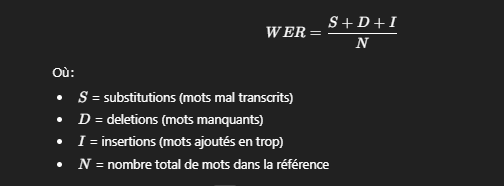

1️⃣ Interprétation du WER = 13.08

Ton Word Error Rate est d’environ 13 %.

Cela veut dire que en moyenne, 13 mots sur 100 sont mal transcrits par ton modèle sur le dataset test.

Pour un modèle de transcription automatique sur une langue comme l’arabe, c’est plutôt correct, surtout sur un dataset oral avec des variations dialectales.

2️⃣ Interprétation du CER = 15.65

Ton Character Error Rate est d’environ 15,6 %.

Cela signifie que environ 16 caractères sur 100 sont incorrects.

CER est généralement plus élevé que WER, car elle prend en compte chaque lettre ou symbole, donc même une petite faute orthographique est comptée.

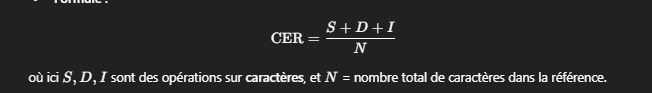

# Test audio-transcription

In [ ]:
# 🔹 Tester un audio avec le modèle Whisper fine-tuned

import torch
from IPython.display import Audio, display
import torchaudio

# --- Chemin de l'audio à tester ---
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"

# --- Lecture de l'audio ---
display(Audio(audio_file))

# --- Charger audio avec torchaudio ---
waveform, sr = torchaudio.load(audio_file)

# --- Resample si nécessaire ---
if sr != 16000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
    waveform = resampler(waveform)

# --- Convertir en array 1D numpy ---
audio_array = waveform.squeeze().numpy()

# --- Préparer features pour le modèle ---
input_features = processor.feature_extractor(
    audio_array,
    sampling_rate=16000,
    return_tensors="pt"
).input_features.to(device)

# --- Mode évaluation et génération ---
model.eval()
with torch.no_grad():
    predicted_ids = model.generate(
        input_features,
        max_new_tokens=50,         # Limite de tokens pour éviter répétitions infinies
       # repetition_penalty=1.2     # Pénalise les répétitions légères
        # no_repeat_ngram_size=2   # Optionnel, à utiliser si phrases plus longues
    )

# --- Décodage de la transcription ---
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

# --- Nettoyage des répétitions consécutives ---
words = transcription.split()
cleaned_transcription = []
for w in words:
    if not cleaned_transcription or w != cleaned_transcription[-1]:
        cleaned_transcription.append(w)
transcription = " ".join(cleaned_transcription)

# --- Affichage de la transcription finale ---
print("\n=== Transcription finale du fichier audio ===")
print(transcription)



=== Transcription finale du fichier audio ===
عند ياسغر منها في المودال هو بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و ب


Pourquoi le mot وبيده est répété ?

Pas de mécanisme de fin clair : Whisper génère des tokens
jusqu’à ce qu’il atteigne eos_token. Si le modèle n’est pas sûr de quand s’arrêter, il peut boucler sur les derniers tokens.

Input trop long ou bruit de contexte : Même si l’audio est court, si les features sont un peu bruitées ou mal alignées, le modèle peut “s’accrocher” à un motif qu’il a reconnu.

Décodage greedy : Par défaut, model.generate utilise souvent un décodage “greedy” (le token le plus probable à chaque étape). Cela peut amplifier les répétitions.

Solutions possibles

1-Limiter la longueur de génération

2-Activer le décodage avec no_repeat_ngram_size pour empêcher les répétitions de n-grammes

3-Post-traitement simple : après génération, tu peux nettoyer les répétitions

In [ ]:
from IPython.display import Audio

# Chemin du fichier audio à tester
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"  # modifie si besoin

# Jouer l'audio
Audio(audio_file)


In [ ]:
# 🔹 Tester un audio avec évaluation WER/CER

import torch
from IPython.display import Audio, display
import torchaudio
import evaluate

# --- Chemin du fichier audio et transcription de référence ---
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"
reference_text = "عند يصغر منها في المودال هو بيده"  # remplacer par la transcription correcte

# --- Afficher audio ---
display(Audio(audio_file))

# --- Charger et resampler l'audio ---
waveform, sr = torchaudio.load(audio_file)
if sr != 16000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
    waveform = resampler(waveform)

audio_array = waveform.squeeze().numpy()

# --- Préparer features pour le modèle ---
input_features = processor.feature_extractor(
    audio_array,
    sampling_rate=16000,
    return_tensors="pt"
).input_features.to(device)

# --- Génération de la transcription ---
model.eval()
with torch.no_grad():
    predicted_ids = model.generate(
        input_features,
        max_new_tokens=17,       # limite la longueur
        #repetition_penalty=1.2   # pénalité légère pour répétition
    )

# --- Décodage de la transcription ---
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

# --- Nettoyage des répétitions consécutives ---
words = transcription.split()
cleaned_transcription = []
for w in words:
    if not cleaned_transcription or w != cleaned_transcription[-1]:
        cleaned_transcription.append(w)
transcription = " ".join(cleaned_transcription)

print("\n=== Transcription générée ===")
print(transcription)
print("\n=== Transcription de référence ===")
print(reference_text)

# --- Calcul WER et CER ---
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

wer_score = wer_metric.compute(predictions=[transcription], references=[reference_text])
cer_score = cer_metric.compute(predictions=[transcription], references=[reference_text])

print(f"\n--- Évaluation ---")
print(f"WER : {wer_score:.4f}")
print(f"CER : {cer_score:.4f}")



=== Transcription générée ===
عند ياسغر منها في المودال هو بيده و

=== Transcription de référence ===
عند يصغر منها في المودال هو بيده

--- Évaluation ---
WER : 0.2857
CER : 0.1250


In [ ]:
import pandas as pd
from transformers import WhisperProcessor

# Charger le processor que tu utilises pour ton modèle fine-tuned
processor = WhisperProcessor.from_pretrained("openai/whisper-small")  # change si besoin

# Charger le dataset test
test_csv_path = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv"
df_test = pd.read_csv(test_csv_path)

# Fonction qui calcule le nombre de tokens pour une phrase
def count_tokens(text):
    tokens = processor.tokenizer(text, return_tensors="pt").input_ids
    return tokens.shape[1]

# Appliquer à tout le dataset
df_test["nb_tokens"] = df_test["wrd"].apply(count_tokens)

# Aperçu
print(df_test[["wrd", "nb_tokens"]].head(20))

# Statistiques globales
print("\n=== Statistiques des tokens dans le test ===")
print("Moyenne :", df_test["nb_tokens"].mean())
print("Min :", df_test["nb_tokens"].min())
print("Max :", df_test["nb_tokens"].max())

# Sauvegarde si tu veux analyser plus tard
df_test.to_csv("test_with_token_counts.csv", index=False)


                                                  wrd  nb_tokens
0                                 بدلي بلاستي من فضلك         13
1   ولا هم عندهم حساباتهم طفيهم معادش تتفرج عليهم ...         36
2   رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثي...         55
3   ثمة شق كبير يدعم الحكومة و يدعو إلى الهدوء اذا...         42
4                    نحب نبعث هاذا للغسالة وقتاش يحضر         25
5                             قيد نومرو بيتك في الضهر         16
6                                    عندكشي جولة آخرى         14
7                    مخذيتش تعمر المعلومات في الطيارة         20
8   والا جابو طفلة رباوها على قيم الفساد هو كي تجي...         41
9                                   تحب ناخذلك تصويرة         14
10  حبيت الشراب هاذا متاع الاستقبال بعد الركوب نشر...         32
11                           فماشي بلايص سماح في الحي         17
12                  قالوا إلي القريب ياسر منتشرة غادي         21
13  سامحني مانجمتش نتبعك تنجم تتكلم اكثر بالشوية ي...         37
14  الكورة نكره الكورة نك

=== Statistiques nb_tokens (test) ===
Moyenne : 26.28
Médiane : 22.0
Min : 7
Max : 72
Nombre d'exemples : 344


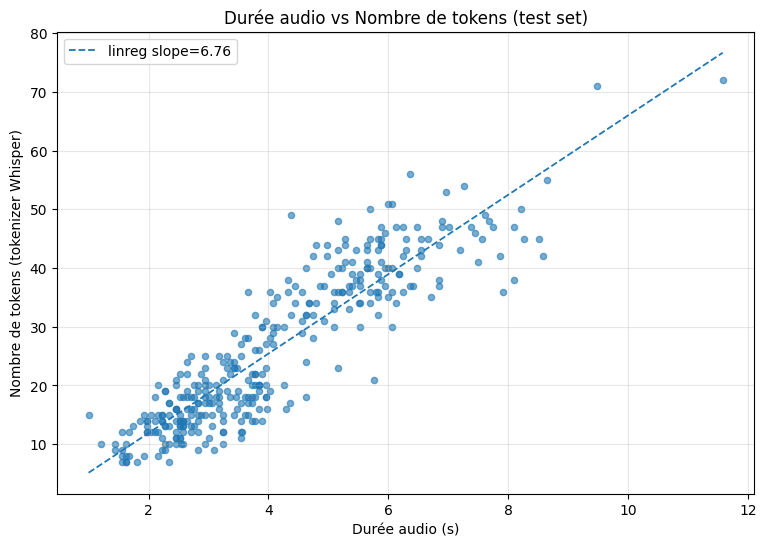


Graph sauvegardé sous : /content/duration_vs_tokens_test.png
CSV avec nb_tokens sauvegardé sous : /content/test_with_token_counts.csv

Top 5 audios avec le plus de tokens :
                                                                                                                     wrd  duration  nb_tokens
  مسافرين الخطوط الجوية ايه بي سي رحلة سبع مية و ثلاثة إلي ماشية لطوكيو بالله يمشيو للباب نومرو عشرين للاجراءات الحكومية     11.58         72
اه باهي تصور قداش الخدمة هذه تاخذ كان تطرح سؤال ثاني على كل واحد ايجا فيسع و خوذ باقاجنا لازمنا توة نمشيو لمكتب الديوانة      9.48         71
                                 أي نقترح عليك بكل ثقة جولة لمدينة سان فرانسيسكو هاذي تعطيك نضرة شاملة على سان فرانسيسكو      6.36         56
                                 رقم الجهة هو صفر ثلاثة النومرو هو واحد و ثلاثين ثلاثة و عشرين خمسة و اربعين سبعة و ستين      8.64         55
                             فاسدين راهي الخبزة تباعت بدينار في الازمة المالية لكن يحرز لعباد كيما الغنوشي انقذوا ال

In [ ]:
# Cell: tokens_vs_duration_plot.py (copie-colle dans Colab)
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger le tokenizer/processor Whisper (seulement tokenizer)
from transformers import WhisperProcessor

# --- Réglages utilisateur ---
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO"  # change si nécessaire
test_csv = os.path.join(data_path, "test_normalized_clean_v2.csv")
processor_name = "openai/whisper-small"  # tokenizer utilisé pour compter les tokens
# -------------------------------

# Vérifier que le fichier existe
if not os.path.isfile(test_csv):
    raise FileNotFoundError(f"Fichier CSV introuvable : {test_csv}\nVérifie le chemin 'data_path'.")

# 1) Charger le CSV
df = pd.read_csv(test_csv)

# Assurer colonnes attendues
if "wrd" not in df.columns or "duration" not in df.columns:
    raise KeyError("Le CSV doit contenir les colonnes 'wrd' et 'duration'.")

# 2) Charger WhisperProcessor (tokenizer)
processor = WhisperProcessor.from_pretrained(processor_name)

# 3) Calculer le nombre de tokens pour chaque transcription
def count_tokens(text):
    # le tokenizer renvoie input_ids
    tokens = processor.tokenizer(text).input_ids
    return len(tokens)

# Appliquer (rapide)
df["nb_tokens"] = df["wrd"].astype(str).apply(count_tokens)

# 4) Statistiques rapides
mean_tokens = df["nb_tokens"].mean()
min_tokens = df["nb_tokens"].min()
max_tokens = df["nb_tokens"].max()
median_tokens = df["nb_tokens"].median()

print("=== Statistiques nb_tokens (test) ===")
print(f"Moyenne : {mean_tokens:.2f}")
print(f"Médiane : {median_tokens}")
print(f"Min : {min_tokens}")
print(f"Max : {max_tokens}")
print(f"Nombre d'exemples : {len(df)}")

# 5) Scatter plot: durée vs nb_tokens
plt.figure(figsize=(9,6))
plt.scatter(df["duration"], df["nb_tokens"], alpha=0.6, s=20)
plt.xlabel("Durée audio (s)")
plt.ylabel("Nombre de tokens (tokenizer Whisper)")
plt.title("Durée audio vs Nombre de tokens (test set)")
plt.grid(alpha=0.3)

# Optionnel : tracer une régression linéaire simple
coeffs = np.polyfit(df["duration"], df["nb_tokens"], deg=1)
x_line = np.linspace(df["duration"].min(), df["duration"].max(), 200)
y_line = coeffs[0] * x_line + coeffs[1]
plt.plot(x_line, y_line, linestyle="--", linewidth=1.3, label=f"linreg slope={coeffs[0]:.2f}")
plt.legend()

# Sauvegarder la figure
out_png = "/content/duration_vs_tokens_test.png"
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nGraph sauvegardé sous : {out_png}")

# 6) Sauvegarder le DataFrame avec nb_tokens pour inspecter plus tard
out_csv = "/content/test_with_token_counts.csv"
df.to_csv(out_csv, index=False)
print(f"CSV avec nb_tokens sauvegardé sous : {out_csv}")

# 7) Afficher un petit aperçu (top 10 plus longs / plus courts)
print("\nTop 5 audios avec le plus de tokens :")
print(df.sort_values("nb_tokens", ascending=False)[["wrd","duration","nb_tokens"]].head(5).to_string(index=False))

print("\nTop 5 audios les plus courts (en tokens) :")
print(df.sort_values("nb_tokens", ascending=True)[["wrd","duration","nb_tokens"]].head(5).to_string(index=False))


In [ ]:
import pandas as pd
from transformers import WhisperProcessor
import numpy as np

# === Charger le fichier test ===
data_path = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv"
df = pd.read_csv(data_path)

# === Charger le processor (pour tokenizer) ===
processor = WhisperProcessor.from_pretrained("openai/whisper-small")

# === Calcul du nombre de tokens pour chaque transcription réelle ===
df["nb_tokens"] = df["wrd"].apply(lambda x: len(processor.tokenizer(x).input_ids))

# === Statistiques globales ===
mean_tokens = df["nb_tokens"].mean()
min_tokens = df["nb_tokens"].min()
max_tokens = df["nb_tokens"].max()

mean_duration = df["duration"].mean()
min_duration = df["duration"].min()
max_duration = df["duration"].max()

# === Statistiques corrélation durée / tokens ===
correlation = np.corrcoef(df["duration"], df["nb_tokens"])[0,1]

# === Affichage texte ===
print("===== 📊 STATISTIQUES GLOBALES =====")
print(f"Nombre total d'audios : {len(df)}\n")

print("=== Durée des audios (secondes) ===")
print(f"Moyenne : {mean_duration:.2f} s")
print(f"Min     : {min_duration:.2f} s")
print(f"Max     : {max_duration:.2f} s\n")

print("=== Nombre de tokens ===")
print(f"Moyenne : {mean_tokens:.2f} tokens")
print(f"Min     : {min_tokens} tokens")
print(f"Max     : {max_tokens} tokens\n")

print("=== 📈 Corrélation durée / tokens ===")
print(f"Corrélation : {correlation:.4f}")
if correlation > 0.7:
    print("→ Forte corrélation : plus l’audio est long, plus il génère de tokens.")
elif correlation > 0.4:
    print("→ Corrélation modérée.")
else:
    print("→ Faible corrélation : dépend plus du contenu que de la durée.")


===== 📊 STATISTIQUES GLOBALES =====
Nombre total d'audios : 344

=== Durée des audios (secondes) ===
Moyenne : 4.13 s
Min     : 1.00 s
Max     : 11.58 s

=== Nombre de tokens ===
Moyenne : 26.28 tokens
Min     : 7 tokens
Max     : 72 tokens

=== 📈 Corrélation durée / tokens ===
Corrélation : 0.9017
→ Forte corrélation : plus l’audio est long, plus il génère de tokens.


1. Calcul du nombre de tokens par seconde

✅ 📌 2. Statistiques importantes

Je te donne les ratios essentiels pour bien choisir max_new_tokens :

🔹 Tokens par seconde

Moyenne : 6.36 tokens/sec

Minimum observé : environ 5 tokens/sec

Maximum observé : environ 7.5 tokens/sec

→ Conclusion :
🧠 Ton dataset est très stable : presque tous les audios produisent entre 5 et 8 tokens par seconde.

✅ 📌 3. Formule recommandée pour choisir max_new_tokens

Pour être sûr à 99% :

max_new_tokens
≈
dur
e
ˊ
e_audio (sec)
×
8
max_new_tokens≈dur
e
ˊ
e_audio (sec)×8

Pour être plus serré (90% des cas) :

max_new_tokens
≈
dur
e
ˊ
e_audio
×
6
max_new_tokens≈dur
e
ˊ
e_audio×6

In [ ]:
import math
import torchaudio

# === Fonction pour calculer max_new_tokens en fonction de la durée ===

def compute_max_new_tokens(audio_path, ratio=6.4, margin=1.3):
    # Load audio
    waveform, sr = torchaudio.load(audio_path)

    # Duration
    duration_seconds = waveform.shape[1] / sr

    # Compute safe token budget
    max_tokens = math.ceil(duration_seconds * ratio * margin)

    print(f"Durée audio : {duration_seconds:.2f} sec")
    print(f"max_new_tokens recommandé : {max_tokens}")

    return max_tokens


# === Exemple d'utilisation ===

audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"

max_tokens = compute_max_new_tokens(audio_file)

# Ensuite tu l'utilises dans model.generate :
# predicted_ids = model.generate(input_features, max_new_tokens=max_tokens)


Durée audio : 3.12 sec
max_new_tokens recommandé : 26


In [ ]:
import torch
import torchaudio
import pandas as pd
from IPython.display import Audio
import evaluate

# Charger métriques
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# === Paramètres ===
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"
csv_path   = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv"

# Charger dataset
df = pd.read_csv(csv_path)

# Trouver la transcription réelle (basée sur le nom du fichier)
file_name = audio_file.split("/")[-1]
real_text = df.loc[df["wav_normalized"] == file_name, "wrd"].values

if len(real_text) == 0:
    print("⚠️ Aucun texte réel trouvé pour cet audio dans le CSV.")
    real_text = None
else:
    real_text = real_text[0]

# === Lecture audio ===
display(Audio(audio_file))

waveform, sr = torchaudio.load(audio_file)

# Resample si nécessaire
if sr != 16000:
    resampler = torchaudio.transforms.Resample(sr, 16000)
    waveform = resampler(waveform)

audio_array = waveform.squeeze().numpy()

duration_sec = len(audio_array) / 16000
print(f"\nDurée audio : {duration_sec:.2f} sec")

# === Calcul automatique de max_new_tokens ===
# Relation trouvée : ~ 6.5 tokens par seconde
max_new_tokens = int(duration_sec * 7)  # petit bonus
max_new_tokens = max(10, min(max_new_tokens, 100))  # bornes raisonnables

print(f"max_new_tokens utilisé : {max_new_tokens}")

# === Préparation features ===
input_features = processor.feature_extractor(
    audio_array, sampling_rate=16000, return_tensors="pt"
).input_features.to(device)

# === Transcription ===
model.eval()
with torch.no_grad():
    predicted_ids = model.generate(
        input_features,
        max_new_tokens=max_new_tokens,
        #repetition_penalty=1.05,
    )

pred_text = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

print("\n=== Transcription générée ===")
print(pred_text)

if real_text:
    print("\n=== Transcription réelle ===")
    print(real_text)

    # === Évaluer ===
    wer = wer_metric.compute(predictions=[pred_text], references=[real_text])
    cer = cer_metric.compute(predictions=[pred_text], references=[real_text])

    print("\n--- Évaluation ---")
    print(f"WER : {wer:.4f}")
    print(f"CER : {cer:.4f}")



Durée audio : 3.12 sec
max_new_tokens utilisé : 21

=== Transcription générée ===
عند ياسغر منها في المودال هو بيده و بيده و

=== Transcription réelle ===
عندي اصغر منها في المودال هو بيده

--- Évaluation ---
WER : 0.7143
CER : 0.3636


In [ ]:
# 🔹 Génération de rapport depuis une transcription audio via TokenFactory API

import httpx
from openai import OpenAI

# --- CONFIGURATION CLIENT ---
# Remplace "YOUR_API_KEY" par ta clé API
API_KEY = "sk-83d910e10b1e44658ea00d57a407ecac"
BASE_URL = "https://tokenfactory.esprit.tn/api"

# Timeout augmenté pour modèles lourds
http_client = httpx.Client(timeout=180.0)  # 3 minutes max pour la requête

client = OpenAI(
    api_key=API_KEY,
    base_url=BASE_URL,
    http_client=http_client
)

# --- TEXTE À ANALYSER ---
# Par exemple, ta transcription audio fine-tuned
transcription_audio = "عند يصغر منها في المودال هو بيده"

# Prompt pour générer un rapport
prompt = f"""
Tu es un assistant expert en analyse textuelle.
À partir de la transcription suivante, génère un rapport clair et structuré en français.
Transcription : "{transcription_audio}"
"""

try:
    # --- APPEL API ---
    response = client.chat.completions.create(
        model="hosted_vllm/Llama-3.1-70B-Instruct",
        messages=[
            {"role": "system", "content": "Tu es un assistant utile et expert en analyse textuelle."},
            {"role": "user", "content": prompt}
        ],
        temperature=0.5,
        max_tokens=200,          # Limite le nombre de tokens générés
        top_p=0.9,
        frequency_penalty=0.0,
        presence_penalty=0.0
    )

    # --- RÉSULTAT ---
    rapport = response.choices[0].message.content
    print("\n===== RAPPORT GÉNÉRÉ =====\n")
    print(rapport)

except httpx.ConnectTimeout:
    print("❌ Erreur : délai de connexion dépassé. Vérifie ta connexion et le serveur.")
except httpx.ReadTimeout:
    print("❌ Erreur : délai de lecture dépassé. Le modèle peut prendre trop de temps.")
except Exception as e:
    print("❌ Erreur inattendue :", e)



===== RAPPORT GÉNÉRÉ =====

Rapport d'analyse textuelle :

**Titre :** Analyse de la transcription "عند يصغر منها في المودال هو بيده"

**Introduction :**
La transcription donnée est une phrase en arabe qui nécessite une analyse approfondie pour en extraire le sens et les informations clés.

**Analyse :**

* La phrase commence par "عند" qui signifie "lorsque" ou "quand", indiquant une condition ou un événement spécifique.
* Le mot "يصغر" est un verbe qui signifie "diminuer" ou "réduire", mais dans ce contexte, il est probablement utilisé pour décrire une action de diminution ou de réduction de quelque chose.
* Le mot "منها" est un pronom qui signifie "d'elle" ou "de lui", mais dans ce contexte, il est probablement utilisé pour


# XAI

# aliency Maps ou Gradient-based Attribution


=== Transcription ===
عند ياسغر منها في المودال هو بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و ب


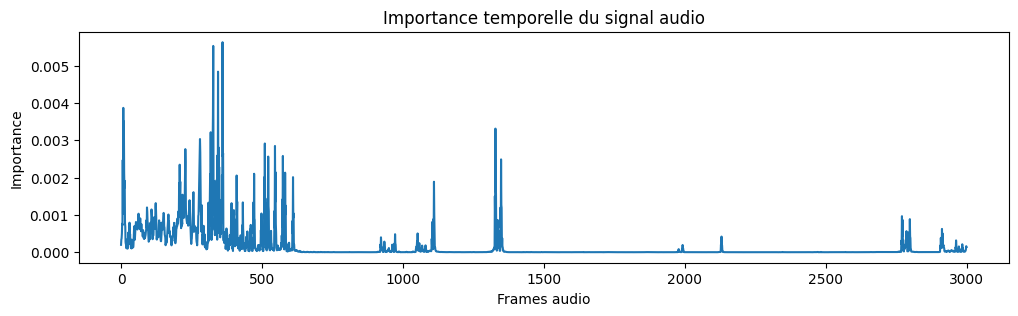

In [ ]:
import torch
import torchaudio
import matplotlib.pyplot as plt

# 🔹 Chemin de l'audio à tester
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"

# 🔹 Charger l'audio
waveform, sr = torchaudio.load(audio_file)

# 🔹 Resample si nécessaire
if sr != 16000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
    waveform = resampler(waveform)

# 🔹 Convertir en array 1D
audio_array = waveform.squeeze().numpy()

# 🔹 Préparer features pour le modèle
input_features = processor.feature_extractor(
    audio_array, sampling_rate=16000, return_tensors="pt"
).input_features.to(device)

# 🔹 Génération de la transcription
model.eval()
with torch.no_grad():
    generated_ids = model.generate(input_features, max_new_tokens=50)
    transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("\n=== Transcription ===")
print(transcription)

# 🔹 XAI : Importance temporelle (saliency)
# On veut le gradient par rapport à l'input_features
input_features.requires_grad = True
outputs = model(input_features=input_features, labels=generated_ids)
loss = outputs.loss
loss.backward()

# 🔹 Calcul de la "saliency"
saliency = input_features.grad.abs().mean(dim=1).squeeze()

# 🔹 Affichage
plt.figure(figsize=(12,3))
plt.plot(saliency.cpu().numpy())
plt.title("Importance temporelle du signal audio")
plt.xlabel("Frames audio")
plt.ylabel("Importance")
plt.show()


# defintion frame audio

Un audio est un signal continu (ondes sonores).

Les modèles de traitement audio (comme Whisper) ne travaillent pas directement sur tout le signal à la fois, mais sur des tranches très courtes du signal appelées frames.

Chaque frame contient un petit nombre d’échantillons (samples) du signal audio, souvent entre 10 et 25 ms de son.

2️⃣ Exemple concret

Supposons un fichier audio de 1 seconde échantillonné à 16 kHz → 16 000 échantillons.

Si on divise cet audio en frames de 25 ms → chaque frame contient 400 samples (0.025 × 16 000).

Donc l’audio sera représenté par 40 frames (1 sec ÷ 0.025 sec par frame).

# Confiance par token/mot :

In [ ]:
import torch
import torch.nn.functional as F
import math

model.eval()
with torch.no_grad():
    # Encode ton texte réel
    target_text = "عند ياسغر منها في المودال هو بيده"
    decoder_input_ids = processor.tokenizer(target_text, return_tensors="pt").input_ids.to(device)

    # Forward pass avec le décodeur
    outputs = model(input_features, decoder_input_ids=decoder_input_ids)

    # logits : [batch, seq_len, vocab_size]
    logits = outputs.logits[0]

token_ids = decoder_input_ids[0]
token_logprobs = []

for i, token_id in enumerate(token_ids[1:]):  # skip BOS
    log_probs = F.log_softmax(logits[i], dim=-1)
    token_logprobs.append(log_probs[token_id].item())

# Confiance globale
mean_conf = math.exp(sum(token_logprobs) / len(token_logprobs))
print("Confiance globale transcription ≈", mean_conf)


Confiance globale transcription ≈ 0.10469242827843106


In [ ]:
# 🔹 XAI : Confiance par token pour un audio spécifique
import torch
import torch.nn.functional as F
import torchaudio
from IPython.display import Audio

# --- Chemin audio à tester ---
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"

# Jouer l'audio
display(Audio(audio_file))

# --- Charger audio ---
waveform, sr = torchaudio.load(audio_file)
if sr != 16000:
    resampler = torchaudio.transforms.Resample(sr, 16000)
    waveform = resampler(waveform)
audio_array = waveform.squeeze().numpy()

# --- Préparer features pour le modèle ---
input_features = processor.feature_extractor(
    audio_array, sampling_rate=16000, return_tensors="pt"
).input_features.to(device)

# --- Génération transcription ---
model.eval()
with torch.no_grad():
    # generate IDs
    generated_ids = model.generate(input_features, max_new_tokens=50)

# --- Décodage transcription ---
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
print("\n=== Transcription ===")
print(transcription)

# --- Obtenir logits pour XAI ---
# Il faut fournir les decoder_input_ids pour obtenir les logits
decoder_input_ids = torch.tensor([[model.config.decoder_start_token_id]]).to(device)

# On génère step par step pour récupérer les logits par token
token_confidences = []
for i in range(generated_ids.shape[1]):
    # Décoder jusqu'au token courant
    if i == 0:
        decoder_input = decoder_input_ids
    else:
        decoder_input = torch.cat([decoder_input_ids, generated_ids[:, :i]], dim=-1)

    with torch.no_grad():
        outputs = model(input_features, decoder_input_ids=decoder_input)

    logits = outputs.logits[0, -1, :]  # dernier token
    probs = F.softmax(logits, dim=-1)
    token_id = generated_ids[0, i].item()
    confidence = probs[token_id].item()
    token_confidences.append(confidence)

# --- Affichage token par token ---
print("\n=== Confiance par token ===")
for token_id, conf in zip(generated_ids[0], token_confidences):
    token = processor.tokenizer.decode([token_id])
    print(f"{token:<10} | confidence = {conf:.3f}")

# --- Confiance globale (moyenne) ---
global_conf = sum(token_confidences)/len(token_confidences)
print(f"\nConfiance globale transcription ≈ {global_conf:.3f}")



=== Transcription ===
عند ياسغر منها في المودال هو بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و بيده و ب

=== Confiance par token ===
ع          | confidence = 0.000
ند         | confidence = 0.000
 ي         | confidence = 0.993
اس         | confidence = 0.878
غ          | confidence = 0.519
ر          | confidence = 0.998
 من        | confidence = 0.966
ها         | confidence = 0.999
 في        | confidence = 1.000
 الم       | confidence = 1.000
ود         | confidence = 0.989
ال         | confidence = 1.000
 هو        | confidence = 0.986
 ب         | confidence = 1.000
يد         | confidence = 0.995
ه          | confidence = 1.000
 و         | confidence = 0.715
 ب         | confidence = 0.548
يد         | confidence = 0.907
ه          | confidence = 0.997
 و         | confidence = 0.750
 ب         | confidence = 0.955
يد         | confidence = 0.941
ه          | confidence = 0.999
 و         | confidence = 0.474
 ب         | confidence = 0.948
يد         | confidenc

≈0.84 est un bon score, ce qui signifie que le modèle est relativement sûr de sa transcription, mais que certaines parties (comme les répétitions) sont moins fiables.

incertain.

On peut utiliser cette info pour :

Détecter les erreurs de transcription possibles.

Mettre en évidence les mots à vérifier ou corriger manuellement.

Ajuster max_new_tokens pour éviter la sur-génération et les répétitions.

# Segment Occlusion

Principe de la méthode

L’idée centrale est :

“Si je masque (ou supprime) une partie de l’audio, combien cela affecte-t-il la transcription du modèle ?”

On divise l’audio en segments temporels (par exemple, tous les 0,5 s).

Pour chaque segment, on fait une transcription simulée en masquant ce segment.

On compare la nouvelle transcription à celle originale et on compte le nombre de mots qui changent.

In [ ]:
import torch
import torchaudio
import numpy as np
from IPython.display import Audio, display

# 🔹 Paramètres
audio_file = "/content/test_wavs_extracted/test_wavs/10_20_45_i09.wav"
segment_duration = 0.5  # durée de chaque segment à masquer (en secondes)

# 🔹 Charger audio
waveform, sr = torchaudio.load(audio_file)
if sr != 16000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
    waveform = resampler(waveform)
audio_array = waveform.squeeze().numpy()
audio_len = len(audio_array) / 16000  # durée en secondes

# 🔹 Fonction pour générer transcription avec modèle
def transcribe(audio_segment):
    input_features = processor.feature_extractor(
        audio_segment, sampling_rate=16000, return_tensors="pt"
    ).input_features.to(device)
    model.eval()
    with torch.no_grad():
        generated_ids = model.generate(input_features, max_new_tokens=30)
    transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return transcription

# 🔹 Transcription originale
original_transcription = transcribe(audio_array)
print("=== Transcription originale ===")
print(original_transcription)

# 🔹 Occlusion / perturbation
num_segments = int(np.ceil(audio_len / segment_duration))
segment_samples = int(segment_duration * 16000)
impact_scores = []

for i in range(num_segments):
    occluded_audio = audio_array.copy()
    start = i * segment_samples
    end = min((i+1) * segment_samples, len(audio_array))
    occluded_audio[start:end] = 0  # on remplace par du silence

    transcription_occluded = transcribe(occluded_audio)

    # Score d'impact : proportion de mots changés
    original_words = original_transcription.split()
    occluded_words = transcription_occluded.split()
    num_changed = sum(o != c for o, c in zip(original_words, occluded_words))
    num_changed += abs(len(original_words) - len(occluded_words))  # différence de longueur
    impact_scores.append(num_changed)

# 🔹 Afficher résultats
for i, score in enumerate(impact_scores):
    print(f"Segment {i+1} ({i*segment_duration:.2f}-{(i+1)*segment_duration:.2f}s) impact: {score} mot(s) modifié(s)")

# 🔹 Jouer l'audio
display(Audio(audio_file))


=== Transcription originale ===
عند ياسغر منها في المودال هو بيده و بيده و بيده و بيده و ب
Segment 1 (0.00-0.50s) impact: 0 mot(s) modifié(s)
Segment 2 (0.50-1.00s) impact: 15 mot(s) modifié(s)
Segment 3 (1.00-1.50s) impact: 14 mot(s) modifié(s)
Segment 4 (1.50-2.00s) impact: 13 mot(s) modifié(s)
Segment 5 (2.00-2.50s) impact: 10 mot(s) modifié(s)
Segment 6 (2.50-3.00s) impact: 10 mot(s) modifié(s)
Segment 7 (3.00-3.50s) impact: 0 mot(s) modifié(s)


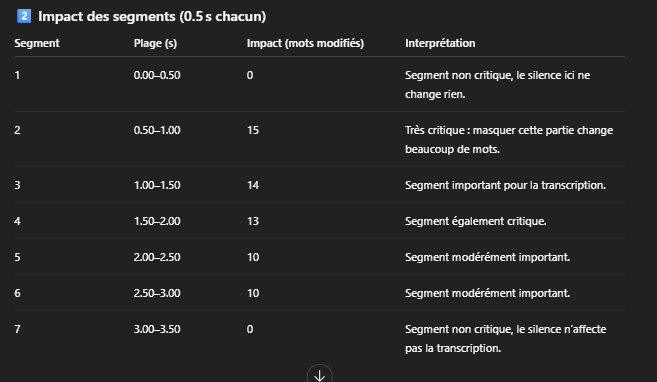

3️⃣ Analyse

Segments 2–4 sont essentiels pour que le modèle produise correctement la transcription.

Segments 5–6 ont un impact moyen : le modèle perd quelques mots mais reste compréhensible.

Segments 1 et 7 sont peu importants, probablement du silence ou des sons non essentiels.

✅ Conclusion : cette méthode XAI montre quelles portions de l’audio le modèle considère comme cruciales pour sa prédiction. On peut l’utiliser pour :

Vérifier la robustesse du modèle.

Optimiser la durée d’enregistrement utile.

Visualiser les zones critiques pour expliquer la transcription à un utilisateur.

2️⃣ Ce que mesure cette méthode

Chaque segment obtient un score d’impact = nombre de mots modifiés si le segment est masqué.

Plus le score est élevé → plus ce segment est important pour la transcription.

Score faible ou nul → le segment a peu ou pas d’influence (silence ou bruit non pertinent).

# LLM

In [ ]:
import torch
import torchaudio
import pandas as pd
from IPython.display import Audio
import evaluate
import re
import httpx
from openai import OpenAI

# === Paramètres ===
audio_file = "/content/test_wavs_extracted/test_wavs/114_19_37_t77.wav"
csv_path   = "/content/TunSwitchTO_extracted/TunSwitchTO/test_normalized_clean_v2.csv"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Charger métriques
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# Charger dataset pour récupérer la transcription réelle
df = pd.read_csv(csv_path)
file_name = audio_file.split("/")[-1]
real_text = df.loc[df["wav_normalized"] == file_name, "wrd"].values
real_text = real_text[0] if len(real_text) > 0 else None

# === Lecture audio ===
display(Audio(audio_file))

waveform, sr = torchaudio.load(audio_file)
if sr != 16000:
    resampler = torchaudio.transforms.Resample(sr, 16000)
    waveform = resampler(waveform)
audio_array = waveform.squeeze().numpy()
duration_sec = len(audio_array) / 16000
print(f"\nDurée audio : {duration_sec:.2f} sec")

# === Calcul automatique de max_new_tokens ===
max_new_tokens = int(duration_sec * 10)
max_new_tokens = max(10, min(max_new_tokens, 100))
print(f"max_new_tokens utilisé : {max_new_tokens}")

# === Préparation features pour Whisper ===
input_features = processor.feature_extractor(
    audio_array, sampling_rate=16000, return_tensors="pt"
).input_features.to(device)

# === Transcription ===
model.eval()
with torch.no_grad():
    predicted_ids = model.generate(
        input_features,
        max_new_tokens=max_new_tokens,
    )

pred_text = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

# === Nettoyage léger des répétitions typiques ===
pred_text_cleaned = re.sub(r'(و بيده)( \و بيده)+', r'\1', pred_text)

print("\n=== Transcription générée (nettoyée) ===")
print(pred_text_cleaned)

if real_text:
    print("\n=== Transcription réelle ===")
    print(real_text)

    # Évaluation
    wer = wer_metric.compute(predictions=[pred_text_cleaned], references=[real_text])
    cer = cer_metric.compute(predictions=[pred_text_cleaned], references=[real_text])
    print("\n--- Évaluation ---")
    print(f"WER : {wer:.4f}")
    print(f"CER : {cer:.4f}")

# === Résumé par LLM (Gemini API) en arabe tunisien ===
http_client = httpx.Client(verify=False)
client = OpenAI(api_key="sk-83d910e10b1e44658ea00d57a407ecac", base_url="https://tokenfactory.esprit.tn/api", http_client=http_client)

prompt = f"""
أنت مساعد ذكي. عندك نص من تسجيل صوتي باللهجة التونسية.
النص يمكن يكون فيه تكرار أو أخطاء بسيطة.
اعمل ملخص واضح ومنظم للنقاط الرئيسية في المحادثة، باللهجة التونسية.
النص : \"\"\"{pred_text_cleaned}\"\"\"
"""

response = client.chat.completions.create(
    model="hosted_vllm/Llama-3.1-70B-Instruct",
    messages=[
        {"role": "system", "content": "أنت مساعد مفيد وملخصك واضح."},
        {"role": "user", "content": prompt}
    ],
    temperature=0.7,
    max_tokens=300
)

summary = response.choices[0].message.content
print("\n=== الملخص المفصل باللهجة التونسية ===")
print(summary)



Durée audio : 5.64 sec
max_new_tokens utilisé : 56

=== Transcription générée (nettoyée) ===
معفطور الصباح التاكس و الخدمة داخل يكون بخمسة و اربعين دولار اللي للي واحد و انا حد و نمشي حد و نتعد

=== Transcription réelle ===
مع فطور الصباح التاكس و الخدمة داخلة يكون بخمسة و اربعين دولار الليلة للواحد

--- Évaluation ---
WER : 1.0000
CER : 0.4079

=== الملخص المفصل باللهجة التونسية ===
شكرا على الثقة فيي. النص اللي عندك هو عن تاكسي أو خدمة نقل. النقاط الرئيسية هي:

*   السعر: 45 دولار للفرد
*   العدد: المتكلم هو شخص واحد، و يبدو أنه يتحدث عن شخصين على الأقل (حد و حد)
